# Анализ лояльности пользователей Яндекс Афиши с помощью Python

- Автор: Смородина Я.А.
- Дата: 23/10/2026

## Цели и задачи проекта

### Цель:
Провести исследовательский анализ данных, чтобы понять, какие пользователи с большей вероятностью возвращаются на платформу и делают заказы повторно

### Задачи:
1. Изучить предоставленный датасет.
2. Определить объем и качество предоставленных данных.
3. Провести предобработку данных.
4. Провести исследовательский анализ данных:
    - сформировать профиль пользователя, выделив признаки и факторы, которые могут влиять на повторные заказы;
    - выяснить как распределены данные и какие закономерности в них наблюдаются;
    - узнать какие признаки влияют на количество заказов;
5. Сформулировать выводы по проведенному анализу;

## Описание данных

Для анализа предоставлен доступ к базе данных сервиса Яндекс Афиша, в которой хранятся данные о пользователях и совершенных ими заказах. Для удобства дельнейшего анализа данные были собраны в единый датасет `df`.

### Описание датасета `df`:

- `user_id` — уникальный идентификатор пользователя, совершившего заказ;
- `device_type_canonical` — тип устройства, с которого был оформлен заказ ( `mobile` — мобильные устройства, `desktop` - стационарные);
- `order_id` — уникальный идентификатор заказа;
- `order_dt` — дата создания заказа;
- `order_ts` — дата и время создания заказа;
- `currency_code` — валюта оплаты;
- `revenue` — выручка от заказа;
- `tickets_count` — количество купленных билетов;
- `days_since_prev` — количество дней от предыдущей покупки пользователя, для пользователей с одной покупкой — значение пропущено;
- `event_id` — уникальный идентификатор мероприятия;
- `service_name` — название билетного оператора;
- `event_type_main` — основной тип мероприятия (театральная постановка, концерт и так далее);
- `region_name` — название региона, в котором прошло мероприятие;
- `city_name` — название города, в котором прошло мероприятие;

## Структура проекта

1. Загрузка данных и знакомство с ними.
2. Предобработка данных.
3. Исследовательский анализ данных.
4. Итоговый вывод и рекомендации.

## 1. Загрузка данных и знакомство с ними.

In [1]:
#Подготовка к подключению к БД
!pip install sqlalchemy 
!pip install psycopg2-binary
!pip install python-dotenv

# Импорт load_dotenv.
from dotenv import load_dotenv 

# Импорт библиотеки для работы с окружением.
import os  

#Устанавливаем нужные библиотеки
import pandas as pd
from sqlalchemy import create_engine

import numpy as np

#Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Подключение к БД

# Загрузка переменных из .env
load_dotenv(dotenv_path='/Users/yana/pract/M2/M2.2/.env')

user = os.getenv('DB_USER')
pwd = os.getenv('DB_PASSWORD')
host = os.getenv('DB_HOST')
port = os.getenv('DB_PORT')
db = os.getenv('DB_NAME')

db_config = {'user': user, # имя пользователя
             'pwd': pwd, # пароль
             'host': host,
             'port': port, # порт подключения
             'db': db # название базы данных
             }
connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
)

engine = create_engine(connection_string)

In [3]:
#Извлекаем данные 
query = '''SELECT 
  user_id,
  device_type_canonical,
  order_id,
  created_dt_msk AS order_dt,
  created_ts_msk AS order_ts,
  currency_code,
  revenue,
  tickets_count,
  created_dt_msk::DATE - LAG(created_dt_msk::DATE) OVER(
  	PARTITION BY user_id
  	ORDER BY created_dt_msk)
  		AS days_since_prev,
  purchases.event_id,
  event_name_code AS event_name,
  event_type_main,
  service_name,
  region_name,
  city_name
FROM 
  afisha.purchases
INNER JOIN afisha.events 
  ON afisha.purchases.event_id = afisha.events.event_id
LEFT JOIN afisha.city 
  ON afisha.events.city_id = afisha.city.city_id
LEFT JOIN afisha.regions 
  ON afisha.city.region_id = afisha.regions.region_id
WHERE 
  device_type_canonical IN ('mobile', 'desktop')
  AND 
  event_type_main != 'фильм'
ORDER BY user_id;'''

df = pd.read_sql_query(query, con=engine)

In [4]:
#Смотрим на сам датасет
df.head(10)

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк
5,000898990054619,mobile,2613713,2024-10-23,2024-10-23 15:12:00,rub,902.74,3,19.0,500862,9cc55c15-4375-4129-9979-3129688ba1b4,концерты,Облачко,Лугоградская область,Кристалевск
6,00096d1f542ab2b,desktop,6636941,2024-08-15,2024-08-15 16:48:48,rub,917.83,4,NaN,201953,2f98d69f-4e60-4ffc-8f16-e539383526b1,театр,Край билетов,Каменевский регион,Глиногорск
7,000a55a418c128c,mobile,4657981,2024-09-29,2024-09-29 19:39:12,rub,47.78,1,NaN,265857,0d876e01-851e-458b-ba61-753e0e0c4063,театр,Лучшие билеты,Поленовский край,Дальнозолотск
8,000a55a418c128c,mobile,4657952,2024-10-15,2024-10-15 10:29:04,rub,74.84,2,16.0,271579,ddc795f8-7ef8-4eb0-b299-cb3e6ee24ba1,театр,Лучшие билеты,Поленовский край,Дальнозолотск
9,000cf0659a9f40f,mobile,6818017,2024-06-20,2024-06-20 10:35:26,rub,1421.91,4,NaN,516728,11be386f-7cb7-4aa1-a8e4-ba73a29c1af2,концерты,Лови билет!,Широковская область,Радужнополье


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

In [6]:
#Cоздаем копию датасета до преобразования для возможности проверить сделанные изменения после предобработки
temp = df.copy() 
len(temp)

290611

### Промежуточный вывод

Датасет `df` содержит 15 столбцов и 290611 строк, в которых представлена информация о пользователях, их заказах и мероприятиях.

После первичного анализа данных можно сделать следующие выводы:
- Пропуски содержатся только в столбце `days_since_prev`, они означают что клиент совершил всего один заказ через сервис, c ними ничего делать не будем;
- Столбцы `device_type_canonical`, `currency_code`, и `event_type_main` содержат категориальный признак, их можно привести к типу category;
- Столбец `order_id` и `event_id` приведем к типу object для удобства дальнейшего изучения;
- Выручка представлена в двух разных валютах, необходимо привести ее к единой валюте;
- Можно понизить разрядность в столбцах `revenue`, `days_since_prev`, `tickets_count`;

Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

## 2. Предобработка данных

In [7]:
#Переведем валюту
df_rev = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')
df_rev['data'] = pd.to_datetime(df_rev['data']) 
print(df_rev)

df = df.merge(df_rev, left_on=['order_dt', 'currency_code'],  
    right_on=['data', 'cdx'], how='left')

df[df['currency_code'] == 'kzt'].head(10)

          data  nominal     curs  cdx
0   2024-01-10      100  19.9391  kzt
1   2024-01-11      100  19.7255  kzt
2   2024-01-12      100  19.5839  kzt
3   2024-01-13      100  19.4501  kzt
4   2024-01-14      100  19.4501  kzt
..         ...      ...      ...  ...
352 2024-12-27      100  19.2705  kzt
353 2024-12-28      100  19.5105  kzt
354 2024-12-29      100  19.4860  kzt
355 2024-12-30      100  19.4860  kzt
356 2024-12-31      100  19.4860  kzt

[357 rows x 4 columns]


,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name,data,nominal,curs,cdx
70,0033403583a55ed,mobile,7850214,2024-09-17,2024-09-17 16:52:06,kzt,518.10,4,20.0,559919,f5ec2467-ee48-42f3-89a0-a2d90d1d6fce,другое,Билеты без проблем,Верхоречная область,Серебрянка,2024-09-17,100.0,19.0125,kzt
89,0040e12d70fae81,desktop,8634925,2024-09-02,2024-09-02 19:49:14,kzt,347.18,3,39.0,559476,61ec7c0e-ea0c-4a3e-a63a-09cbe1bc6177,другое,Билеты без проблем,Верхоречная область,Серебрянка,2024-09-02,100.0,18.9330,kzt
96,0054b38b2653e6e,mobile,7625522,2024-09-09,2024-09-09 18:06:04,kzt,328.77,4,NaN,559582,524f434e-0381-4f47-9688-7c4e41961b65,другое,Билеты без проблем,Верхоречная область,Серебрянка,2024-09-09,100.0,18.5991,kzt
277,00f4f5244501ce6,mobile,720419,2024-06-11,2024-06-11 20:15:57,kzt,22021.55,5,NaN,536826,76af4f88-c554-4e9e-9df4-1cc8aeec8959,концерты,Мой билет,Верхоречная область,Серебрянка,2024-06-11,100.0,19.8928,kzt
460,01370a0e9c1a7d5,desktop,5227657,2024-06-04,2024-06-04 13:28:17,kzt,7397.66,4,1.0,533803,0686ac7b-6f3e-4177-bb73-16b54acd1223,концерты,Мой билет,Шанырский регион,Широковка,2024-06-04,100.0,19.9833,kzt
461,01370a0e9c1a7d5,mobile,2229811,2024-06-04,2024-06-04 13:19:47,kzt,7397.66,4,0.0,533803,0686ac7b-6f3e-4177-bb73-16b54acd1223,концерты,Мой билет,Шанырский регион,Широковка,2024-06-04,100.0,19.9833,kzt
462,01370a0e9c1a7d5,mobile,2229782,2024-06-04,2024-06-04 13:17:35,kzt,3698.83,2,0.0,533803,0686ac7b-6f3e-4177-bb73-16b54acd1223,концерты,Мой билет,Шанырский регион,Широковка,2024-06-04,100.0,19.9833,kzt
463,01370a0e9c1a7d5,mobile,2229753,2024-06-04,2024-06-04 13:26:32,kzt,5548.24,3,0.0,533803,0686ac7b-6f3e-4177-bb73-16b54acd1223,концерты,Мой билет,Шанырский регион,Широковка,2024-06-04,100.0,19.9833,kzt
464,01370a0e9c1a7d5,mobile,2229724,2024-06-04,2024-06-04 13:25:28,kzt,7397.66,4,0.0,533803,0686ac7b-6f3e-4177-bb73-16b54acd1223,концерты,Мой билет,Шанырский регион,Широковка,2024-06-04,100.0,19.9833,kzt
515,01370a0e9c1a7d5,mobile,2044298,2024-09-05,2024-09-05 16:15:58,kzt,361.08,4,1.0,561747,27956246-d4a5-4b76-b5db-719831c41591,другое,Мой билет,Шанырский регион,Синеводск,2024-09-05,100.0,18.4217,kzt


In [8]:
#Умножим валюту

df['revenue_rub'] = np.where(df['currency_code'] == 'rub', df['revenue'], df['revenue']*df['curs']/df['nominal'])
df.head(10)

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name,data,nominal,curs,cdx,revenue_rub
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск,NaT,NaN,NaN,NaN,1521.94
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск,NaT,NaN,NaN,NaN,289.45
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск,NaT,NaN,NaN,NaN,1258.57
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск,NaT,NaN,NaN,NaN,8.49
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк,NaT,NaN,NaN,NaN,1390.41
5,000898990054619,mobile,2613713,2024-10-23,2024-10-23 15:12:00,rub,902.74,3,19.0,500862,9cc55c15-4375-4129-9979-3129688ba1b4,концерты,Облачко,Лугоградская область,Кристалевск,NaT,NaN,NaN,NaN,902.74
6,00096d1f542ab2b,desktop,6636941,2024-08-15,2024-08-15 16:48:48,rub,917.83,4,NaN,201953,2f98d69f-4e60-4ffc-8f16-e539383526b1,театр,Край билетов,Каменевский регион,Глиногорск,NaT,NaN,NaN,NaN,917.83
7,000a55a418c128c,mobile,4657981,2024-09-29,2024-09-29 19:39:12,rub,47.78,1,NaN,265857,0d876e01-851e-458b-ba61-753e0e0c4063,театр,Лучшие билеты,Поленовский край,Дальнозолотск,NaT,NaN,NaN,NaN,47.78
8,000a55a418c128c,mobile,4657952,2024-10-15,2024-10-15 10:29:04,rub,74.84,2,16.0,271579,ddc795f8-7ef8-4eb0-b299-cb3e6ee24ba1,театр,Лучшие билеты,Поленовский край,Дальнозолотск,NaT,NaN,NaN,NaN,74.84
9,000cf0659a9f40f,mobile,6818017,2024-06-20,2024-06-20 10:35:26,rub,1421.91,4,NaN,516728,11be386f-7cb7-4aa1-a8e4-ba73a29c1af2,концерты,Лови билет!,Широковская область,Радужнополье,NaT,NaN,NaN,NaN,1421.91


In [9]:
#посмотрим на обущю информацию
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 290611 entries, 0 to 290610
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

In [10]:
#Уберем ненужные столбцы
df_rub = df.drop(columns=['data', 'nominal', 'curs', 'cdx'])
df_rub.head(10)

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name,revenue_rub
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск,1521.94
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск,289.45
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск,1258.57
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск,8.49
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк,1390.41
5,000898990054619,mobile,2613713,2024-10-23,2024-10-23 15:12:00,rub,902.74,3,19.0,500862,9cc55c15-4375-4129-9979-3129688ba1b4,концерты,Облачко,Лугоградская область,Кристалевск,902.74
6,00096d1f542ab2b,desktop,6636941,2024-08-15,2024-08-15 16:48:48,rub,917.83,4,NaN,201953,2f98d69f-4e60-4ffc-8f16-e539383526b1,театр,Край билетов,Каменевский регион,Глиногорск,917.83
7,000a55a418c128c,mobile,4657981,2024-09-29,2024-09-29 19:39:12,rub,47.78,1,NaN,265857,0d876e01-851e-458b-ba61-753e0e0c4063,театр,Лучшие билеты,Поленовский край,Дальнозолотск,47.78
8,000a55a418c128c,mobile,4657952,2024-10-15,2024-10-15 10:29:04,rub,74.84,2,16.0,271579,ddc795f8-7ef8-4eb0-b299-cb3e6ee24ba1,театр,Лучшие билеты,Поленовский край,Дальнозолотск,74.84
9,000cf0659a9f40f,mobile,6818017,2024-06-20,2024-06-20 10:35:26,rub,1421.91,4,NaN,516728,11be386f-7cb7-4aa1-a8e4-ba73a29c1af2,концерты,Лови билет!,Широковская область,Радужнополье,1421.91


In [11]:
#Посмотрим на новый датафрейм
df_rub.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

In [12]:
#Для удобства дальнейшего анализа скорректируем типы данных в столбцах
#Понизим разрядность 
for x in ['revenue','days_since_prev', 'revenue_rub']:
    df_rub[x] = pd.to_numeric(df_rub[x], downcast='float')


df_rub['tickets_count'] = pd.to_numeric(df_rub['tickets_count'], downcast='integer')
 
#Преобразуем категориальные колонки
for y in ['device_type_canonical','currency_code', 'event_type_main']:
    df_rub[y] = df_rub[y].astype('category')
    
#Преобразуем идентификаторы
for z in ['order_id','event_id']:
    df_rub[z] = df_rub[z].astype('object')

In [13]:
df_rub.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  category      
 2   order_id               290611 non-null  object        
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  category      
 6   revenue                290611 non-null  float32       
 7   tickets_count          290611 non-null  int8          
 8   days_since_prev        268678 non-null  float32       
 9   event_id               290611 non-null  object        
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  category      
 12  service_name           290611 non-null  obje

In [14]:
#Посмотрим пропуски

df_rub.isna().sum()

user_id                      0
device_type_canonical        0
order_id                     0
order_dt                     0
order_ts                     0
currency_code                0
revenue                      0
tickets_count                0
days_since_prev          21933
event_id                     0
event_name                   0
event_type_main              0
service_name                 0
region_name                  0
city_name                    0
revenue_rub                  0
dtype: int64

In [15]:
round(df_rub.isna().mean() * 100, 2)

user_id                  0.00
device_type_canonical    0.00
order_id                 0.00
order_dt                 0.00
order_ts                 0.00
currency_code            0.00
revenue                  0.00
tickets_count            0.00
days_since_prev          7.55
event_id                 0.00
event_name               0.00
event_type_main          0.00
service_name             0.00
region_name              0.00
city_name                0.00
revenue_rub              0.00
dtype: float64

In [16]:
#Приведем все названия к нормальному виду
import string
def norm(x):
    if pd.isna(x):  
        return x
    else:  
        x = x.lower()
        x = x.translate(str.maketrans('', '', string.punctuation))
        x = x.replace('  ', ' ')
        return x

df_rub['service_name'] = df_rub['service_name'].apply(norm)
print(df_rub['service_name'])

df_rub['region_name'] = df_rub['region_name'].apply(norm)
print(df_rub['region_name'])


df_rub['city_name'] = df_rub['city_name'].apply(norm)
print(df_rub['city_name'])


0               край билетов
1                  мой билет
2                 за билетом
3                 лови билет
4         билеты без проблем
                 ...        
290606        весь в билетах
290607        весь в билетах
290608             прачечная
290609    билеты без проблем
290610             мой билет
Name: service_name, Length: 290611, dtype: object
0           каменевский регион
1           каменевский регион
2           каменевский регион
3         североярская область
4             озернинский край
                  ...         
290606      каменевский регион
290607      каменевский регион
290608      каменевский регион
290609     широковская область
290610    малиновоярский округ
Name: region_name, Length: 290611, dtype: object
0          глиногорск
1          глиногорск
2          глиногорск
3              озёрск
4         родниковецк
             ...     
290606     глиногорск
290607     глиногорск
290608     глиногорск
290609     ягодиновка
290610      верховино

In [17]:
# Проверяем полные дубликаты в датафрейме 
df_rub.duplicated().sum()

0

In [18]:
# Проверяем неявные дубликаты в датафрейме 
df_rub.duplicated(subset='order_id').sum()

0

In [19]:
#Посмотрим на уникальные категории в датасете
print('Распределение данных по значениям столбца: device_type_canonical')
df_rub['device_type_canonical'].value_counts()

Распределение данных по значениям столбца: device_type_canonical


mobile     232490
desktop     58121
Name: device_type_canonical, dtype: int64

In [20]:
print('Распределение данных в относительных значениях по значениям столбца: device_type_canonical')
round(df_rub['device_type_canonical'].value_counts(normalize=True) * 100, 2)

Распределение данных в относительных значениях по значениям столбца: device_type_canonical


mobile     80.0
desktop    20.0
Name: device_type_canonical, dtype: float64

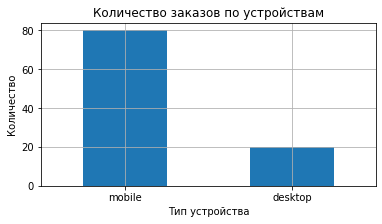

In [21]:
#Визуализируем данные
plt.figure(figsize=(6, 3))
#Создаем график
round(df_rub['device_type_canonical'].value_counts(normalize=True) * 100, 2).plot(
    kind = 'bar',
    rot = 0,
    legend = False,
    title = f'Количество заказов по устройствам')
#Редактируем график
plt.xlabel('Тип устройства')
plt.ylabel('Количество')
plt.grid()

plt.show()

In [22]:
print('Распределение данных по значениям столбца: currency_code')
df_rub['currency_code'].value_counts()

Распределение данных по значениям столбца: currency_code


rub    285542
kzt      5069
Name: currency_code, dtype: int64

In [23]:
print('Распределение данных в относительных значениях по значениям столбца: currency_code')
round(df_rub['currency_code'].value_counts(normalize=True) * 100, 2)

Распределение данных в относительных значениях по значениям столбца: currency_code


rub    98.26
kzt     1.74
Name: currency_code, dtype: float64

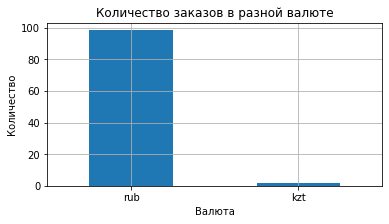

In [24]:
#Визуализируем данные
plt.figure(figsize=(6, 3))
#Создаем график
round(df_rub['currency_code'].value_counts(normalize=True) * 100, 2).plot(
    kind = 'bar',
    rot = 0,
    legend = False,
    title = f'Количество заказов в разной валюте')
#Редактируем график
plt.xlabel('Валюта')
plt.ylabel('Количество')
plt.grid()

plt.show()

In [25]:
print('Распределение данных по значениям столбца: event_type_main')
df_rub['event_type_main'].value_counts().sort_values(ascending=False)

Распределение данных по значениям столбца: event_type_main


концерты    115276
театр        67321
другое       65867
спорт        21911
стендап      13393
выставки      4854
ёлки          1989
Name: event_type_main, dtype: int64

In [26]:
print('Распределение данных в относительных значениях по значениям столбца: event_type_main')
round(df_rub['event_type_main'].value_counts(normalize=True) * 100, 2)

Распределение данных в относительных значениях по значениям столбца: event_type_main


концерты    39.67
театр       23.17
другое      22.67
спорт        7.54
стендап      4.61
выставки     1.67
ёлки         0.68
Name: event_type_main, dtype: float64

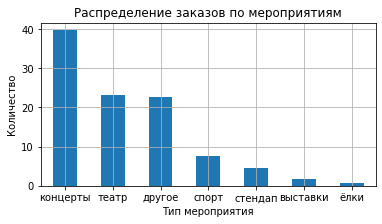

In [27]:
#Визуализируем данные
plt.figure(figsize=(6, 3))
#Создаем график
round(df_rub['event_type_main'].value_counts(normalize=True) * 100, 2).plot(
    kind = 'bar',
    rot = 0,
    legend = False,
    title = f'Распределение заказов по мероприятиям')
#Редактируем график
plt.xlabel('Тип мероприятия')
plt.ylabel('Количество')
plt.grid()

plt.show()

In [28]:
#Посмотрим числовые данные в столбце с выручкой
df_rub['revenue_rub'].describe()

count    290611.000000
mean        555.568359
std         875.455627
min         -90.760002
25%         113.970001
50%         351.140015
75%         802.049988
max       81174.539062
Name: revenue_rub, dtype: float64

In [29]:
#Видим слишком большое максимальное значение, уберем выбросы
filtr_rub = df_rub['revenue_rub'].quantile(0.99)
df_rub = df_rub[df_rub['revenue_rub'] < filtr_rub]
df_rub['revenue_rub'].describe()

count    287604.000000
mean        516.692749
std         509.350220
min         -90.760002
25%         111.675001
50%         343.619995
75%         787.710022
max        2627.000000
Name: revenue_rub, dtype: float64

In [30]:
#Посмотрим на отрицательную выручку
negative_revenue = df_rub[df_rub['revenue_rub'] < 0]
negative_revenue.head(10)

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name,revenue_rub
252,00eb3dc9baa1543,mobile,1594653,2024-06-29,2024-06-29 15:01:43,rub,-2.37,3,NaN,538650,ffe03bc6-0e0c-480d-b037-6a4b55540ab5,другое,билеты без проблем,берёзовская область,златопольск,-2.37
4539,02ea4583333f064,mobile,2360920,2024-09-03,2024-09-03 18:12:58,rub,-0.23,3,0.0,559772,592856bb-09a5-4d32-9534-0e02c6056e44,другое,билеты без проблем,широковская область,лесореченск,-0.23
4544,02ea4583333f064,mobile,2361094,2024-09-04,2024-09-04 09:34:53,rub,-0.15,2,0.0,559772,592856bb-09a5-4d32-9534-0e02c6056e44,другое,билеты без проблем,широковская область,лесореченск,-0.15
8135,043f669c9f734b1,mobile,166780,2024-09-27,2024-09-27 10:00:09,rub,-1.86,3,0.0,567183,9f571dad-b18a-4095-ac76-9db60d8dd97a,другое,лучшие билеты,золотоключевской край,луговинец,-1.86
8136,043f669c9f734b1,mobile,166809,2024-09-27,2024-09-27 10:56:35,rub,-0.62,1,0.0,567183,9f571dad-b18a-4095-ac76-9db60d8dd97a,другое,лучшие билеты,золотоключевской край,луговинец,-0.62
11342,06727636bf2f465,mobile,6620527,2024-06-30,2024-06-30 05:40:34,rub,-1.58,2,24.0,538650,ffe03bc6-0e0c-480d-b037-6a4b55540ab5,другое,билеты без проблем,берёзовская область,златопольск,-1.58
11343,06727636bf2f465,mobile,6620498,2024-07-01,2024-07-01 04:52:51,rub,-1.58,2,1.0,538648,ffe03bc6-0e0c-480d-b037-6a4b55540ab5,другое,билеты без проблем,берёзовская область,златопольск,-1.58
11568,067494310c6617f,mobile,8333963,2024-10-07,2024-10-07 09:32:35,rub,-6.18,4,0.0,569499,b6975aa8-5c9e-408d-bfc8-74fd8189a04f,спорт,билеты в руки,дальнеземская область,теплоозёрск,-6.18
11619,067494310c6617f,mobile,4930755,2024-10-24,2024-10-24 17:48:42,rub,-3.59,1,1.0,568916,b1a3919a-5d3e-4da2-b6f5-eccb480d810c,другое,билеты в руки,малиновая область,зеленополье,-3.59
11622,067494310c6617f,mobile,8350029,2024-10-24,2024-10-24 17:46:44,rub,-10.77,3,0.0,568916,b1a3919a-5d3e-4da2-b6f5-eccb480d810c,другое,билеты в руки,малиновая область,зеленополье,-10.77


In [31]:
print(negative_revenue.count())

user_id                  381
device_type_canonical    381
order_id                 381
order_dt                 381
order_ts                 381
currency_code            381
revenue                  381
tickets_count            381
days_since_prev          349
event_id                 381
event_name               381
event_type_main          381
service_name             381
region_name              381
city_name                381
revenue_rub              381
dtype: int64


Возможно это ошибка данных, для более ясной картины уберем строки с отрицательной выручкой

In [32]:
#Уберем отрицательную выручку 
df_rub = df_rub[df_rub['revenue_rub'] >= 0]
df_rub['revenue_rub'].describe()

count    287223.000000
mean        517.380432
std         509.327637
min           0.000000
25%         112.430000
50%         344.299988
75%         788.640015
max        2627.000000
Name: revenue_rub, dtype: float64

In [33]:
#Построим функцию для гистограммы и ящика с усам площади.
def show_kde(df, column_name, title, ylabel, xlabel, kde, bins):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

    sns.histplot(data=df, x=column_name, kde=kde, bins=bins, ax=ax1)
    ax1.set_title(title)
    ax1.set_ylabel(ylabel)

    sns.boxplot(x=df[column_name], ax=ax2)
    plt.xlabel(xlabel)
    plt.tight_layout()
    plt.grid()
    plt.show()

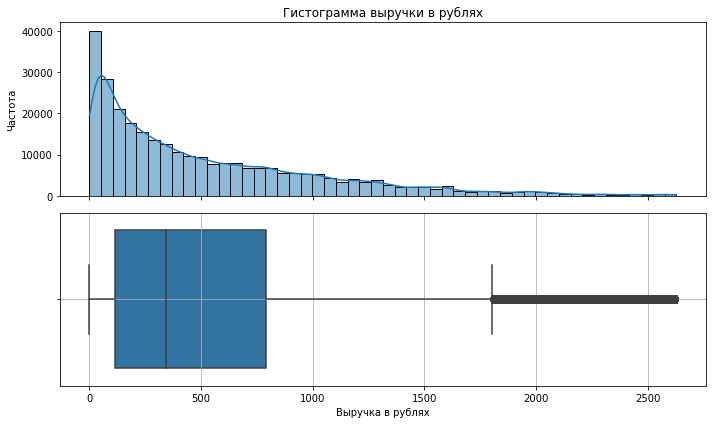

In [34]:
show_kde(df_rub, 'revenue_rub', 'Гистограмма выручки в рублях', 'Частота', 'Выручка в рублях', True, 50)


In [35]:
#Посмотрим на распределение по количеству билетов
df_rub['tickets_count'].describe()

count    287223.000000
mean          2.741159
std           1.163437
min           1.000000
25%           2.000000
50%           3.000000
75%           3.000000
max          57.000000
Name: tickets_count, dtype: float64

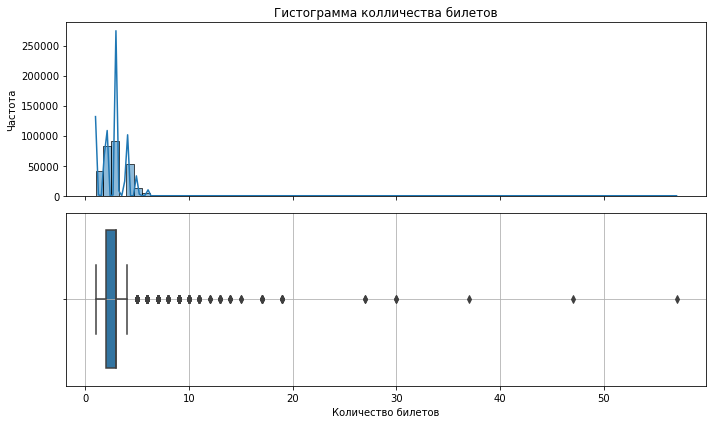

In [36]:
#Построим гистограммы и ящик с усам площади.
show_kde(df_rub, 'tickets_count', 'Гистограмма колличества билетов', 'Частота', 'Количество билетов', True, 75)

In [37]:
df_rub.sort_values(by = 'tickets_count', ascending = False).head(15)

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name,revenue_rub
154001,7eb4fc207ecc10f,desktop,3526517,2024-08-22,2024-08-22 11:23:50,rub,0.000000,57,1.0,557574,05e7dbd5-b93a-4e31-9796-e9cce6741794,другое,билеты без проблем,каменевский регион,глиногорск,0.000000
39413,18e9aead0a393e7,desktop,5338292,2024-09-09,2024-09-09 10:03:45,rub,640.409973,47,0.0,561027,a8f27570-50ca-4ff2-9550-8a5493a335a6,спорт,билеты без проблем,чистогорская область,леснойск,640.409973
154585,7eb4fc207ecc10f,desktop,8151843,2024-09-17,2024-09-17 15:41:39,rub,1147.670044,37,0.0,564789,f840fd65-612b-448d-8483-e12d263a013d,спорт,билеты в руки,медовская область,радужсвет,1147.670044
154186,7eb4fc207ecc10f,desktop,3526633,2024-08-29,2024-08-29 13:03:47,rub,0.000000,30,0.0,215381,2a268292-5064-413f-b080-4b1180acb8af,другое,билеты без проблем,каменевский регион,глиногорск,0.000000
154184,7eb4fc207ecc10f,desktop,3526575,2024-08-29,2024-08-29 13:01:35,rub,0.000000,30,0.0,215381,2a268292-5064-413f-b080-4b1180acb8af,другое,билеты без проблем,каменевский регион,глиногорск,0.000000
86251,3ee7dc2e115847f,desktop,5190653,2024-10-06,2024-10-06 13:06:40,rub,328.489990,27,0.0,575780,eaad35f5-f733-4ab1-a671-e7e86b2748c7,спорт,лови билет,озернинский край,лесоярич,328.489990
86253,3ee7dc2e115847f,desktop,5190682,2024-10-06,2024-10-06 13:08:42,rub,328.489990,27,0.0,575780,eaad35f5-f733-4ab1-a671-e7e86b2748c7,спорт,лови билет,озернинский край,лесоярич,328.489990
153329,7eb4fc207ecc10f,desktop,806259,2024-07-19,2024-07-19 17:06:30,rub,1926.709961,19,0.0,516731,2ccf2683-25a2-4eeb-92f7-d454019a9f30,театр,мой билет,каменевский регион,глиногорск,1926.709961
278869,f6af1139a64d911,mobile,8188499,2024-09-11,2024-09-11 19:28:17,rub,299.019989,19,0.0,542587,fc9cdc7f-f9be-48aa-93d9-053d46dfe72d,другое,билеты без проблем,речицкая область,радужанов,299.019989
190445,9e4f3ad398e1a2e,desktop,3091430,2024-10-15,2024-10-15 14:33:21,rub,190.059998,19,1.0,573817,ec43f81a-3b78-4d52-b838-bfce767be5f2,спорт,билеты без проблем,чистогорская область,леснойск,190.059998


Видим что есть большие заказы по количеству билетов, и у многих выручка нулевая, возможно это какие то социальные категории, для которых по льготам билеты бесплатные например школьники пошли всем классом, или пенсионеры, такие данные убирать не будем.

### Промежуточный вывод

In [38]:
df_rub.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 287223 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                287223 non-null  object        
 1   device_type_canonical  287223 non-null  category      
 2   order_id               287223 non-null  object        
 3   order_dt               287223 non-null  datetime64[ns]
 4   order_ts               287223 non-null  datetime64[ns]
 5   currency_code          287223 non-null  category      
 6   revenue                287223 non-null  float32       
 7   tickets_count          287223 non-null  int8          
 8   days_since_prev        265543 non-null  float32       
 9   event_id               287223 non-null  object        
 10  event_name             287223 non-null  object        
 11  event_type_main        287223 non-null  category      
 12  service_name           287223 non-null  obje

In [39]:
# Проверим сколько удалено строк датасета
a, b = len(temp), len(df_rub)
print(" Было строк в исходном датасете", a,
      '\n', "Осталось строк в датасете после обработки", b,
      '\n', "Удалено строк в датасете после обработки", a-b,
      '\n', "Процент потерь", round((a-b)/a*100, 2))

 Было строк в исходном датасете 290611 
 Осталось строк в датасете после обработки 287223 
 Удалено строк в датасете после обработки 3388 
 Процент потерь 1.17


<b>Промежуточный вывод:</b>
1. <b><i>Общая информация о данных</b></i>
- Исходный датасет содержит 15 столбцов и 290611 строк.
- Размер после всех преобразований 16 столбцов и 287223 строк.
- Готовый датасет после обработки содержит информацию о заказах пользователей (уникальный идентификатор, устройство с которого был сделан заказ, номер заказа, дата и время совершения заказа, выручка в рублях, количество билетов в одном заказе, количество дней с последнего заказа) и о мероприятиях (уникальный идентификатор мероприятия, название мероприятия, названия сервиса который продает билеты, тип мероприятия, место проведения).

2. <b><i>Типы данных</b></i>
- В процессе предобработки данных были скорректированны типы данных: в столбцах revenue,days_since_prev, revenue_rub понижена разрядность с `float64` к `float32`, в столбце tickets_count понижена разряжность с `int64`  к `int8` , в столбцах device_type_canonical, currency_code, event_type_main данные приведены к категориальному типу `category`, колонки с уникальными идентификаторами order_id, event_id были преобразованы в тип `object`.
- Колонки с названиями service_name, region_name, city_name были нормализованы (убраны двойные пробелы, заглавные буквы).
- После преобразований все колонки имеют корректный тип данных.

3. <b><i>Пропуски</b></i>
- Пропуски обнаружены в столбце:
 - `days_since_prev` - 7,55%, они означают что пользователь больше не совершал заказы.
- В столбцах пропуски оставляем что бы не искажать данные для анализа.
 

4. <b><i>Дубликаты</b></i>
- Количество явных дубликатов - 0.
- Количество неявных дубликатов - 0.

5. <b><i>Прочие преобразования</b></i>
  
  Так как в исходном датасете выручка представлена в двух валютах - rub и kzt, для дальнейшей работы был создан столбец revenue_rub, показывающий всю выручку в единой валюте - rub. Так же были выявлены выбросы и отрицательная выручка в столбце revenue_rub, датасет был отфильтрован от выбросов и отрицательной выручки для более ясного дальнейшего анализа. Количество строк в датасете после фильтрации - 287223.


6. <b><i>Итоговое состояние данных</b></i>
- Количество строк после всех преобразований - 287223.
- Данные готовы к дальнейшему анализу, типы данных отображены корректно, пропуски проанализированы и дубликаты удалены, создан дополнительный столбец для удобства анализа данных.
</font>

## 3. Моделирование профиля пользователя

In [40]:
#Построим профиль пользователя
df_rub = df_rub.sort_values(by = 'order_ts')

df_user = df_rub.groupby('user_id').agg(
    first_order = ('order_dt', 'min'),
    last_order = ('order_dt', 'max'),
    device_f_o = ('device_type_canonical', 'first'),
    region_f_o = ('region_name', 'first'),
    service_name_f_o = ('service_name', 'first'),
    event_f_o = ('event_type_main', 'first'),
    sum_orders = ('order_id', 'count'),
    mean_revenue = ('revenue_rub', 'mean'),
    mean_tickets = ('tickets_count', 'mean'),
    mean_days_since_prev = ('days_since_prev', 'mean')
).reset_index()

df_user.head(10)

,user_id,first_order,last_order,device_f_o,region_f_o,service_name_f_o,event_f_o,sum_orders,mean_revenue,mean_tickets,mean_days_since_prev
0,0002849b70a3ce2,2024-08-20,2024-08-20,mobile,каменевский регион,край билетов,театр,1,1521.939941,4.000000,NaN
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,mobile,каменевский регион,мой билет,выставки,2,774.010010,3.000000,75.000000
2,000898990054619,2024-07-13,2024-10-23,mobile,североярская область,лови билет,другое,3,767.213318,2.666667,51.000000
3,00096d1f542ab2b,2024-08-15,2024-08-15,desktop,каменевский регион,край билетов,театр,1,917.830017,4.000000,NaN
4,000a55a418c128c,2024-09-29,2024-10-15,mobile,поленовский край,лучшие билеты,театр,2,61.309998,1.500000,16.000000
5,000cf0659a9f40f,2024-06-20,2024-06-21,mobile,широковская область,лови билет,концерты,13,1175.808472,3.307692,0.083333
6,00147c9209d45d3,2024-06-25,2024-06-25,mobile,каменевский регион,облачко,концерты,2,352.945007,1.500000,0.000000
7,0018ecd8a38a51b,2024-07-25,2024-07-25,mobile,медовская область,билеты без проблем,спорт,1,0.000000,3.000000,NaN
8,00199a573901564,2024-06-17,2024-06-17,mobile,каменевский регион,билеты без проблем,концерты,1,588.119995,4.000000,NaN
9,001e7037d013f0f,2024-07-04,2024-09-29,mobile,златопольский округ,мой билет,другое,3,326.623322,1.333333,43.500000


In [41]:
#Округлим среднее колличество биллетов до целого числа 
df_user['mean_tickets'] = round(df_user['mean_tickets'], 0).astype('int64')
df_user.head(10)

,user_id,first_order,last_order,device_f_o,region_f_o,service_name_f_o,event_f_o,sum_orders,mean_revenue,mean_tickets,mean_days_since_prev
0,0002849b70a3ce2,2024-08-20,2024-08-20,mobile,каменевский регион,край билетов,театр,1,1521.939941,4,NaN
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,mobile,каменевский регион,мой билет,выставки,2,774.010010,3,75.000000
2,000898990054619,2024-07-13,2024-10-23,mobile,североярская область,лови билет,другое,3,767.213318,3,51.000000
3,00096d1f542ab2b,2024-08-15,2024-08-15,desktop,каменевский регион,край билетов,театр,1,917.830017,4,NaN
4,000a55a418c128c,2024-09-29,2024-10-15,mobile,поленовский край,лучшие билеты,театр,2,61.309998,2,16.000000
5,000cf0659a9f40f,2024-06-20,2024-06-21,mobile,широковская область,лови билет,концерты,13,1175.808472,3,0.083333
6,00147c9209d45d3,2024-06-25,2024-06-25,mobile,каменевский регион,облачко,концерты,2,352.945007,2,0.000000
7,0018ecd8a38a51b,2024-07-25,2024-07-25,mobile,медовская область,билеты без проблем,спорт,1,0.000000,3,NaN
8,00199a573901564,2024-06-17,2024-06-17,mobile,каменевский регион,билеты без проблем,концерты,1,588.119995,4,NaN
9,001e7037d013f0f,2024-07-04,2024-09-29,mobile,златопольский округ,мой билет,другое,3,326.623322,1,43.500000


In [42]:
#Добавим бинарные признаки
df_user['is_two'] = df_user['sum_orders'] >= 2
df_user['is_five'] = df_user['sum_orders'] >= 5

df_user.head(10)

,user_id,first_order,last_order,device_f_o,region_f_o,service_name_f_o,event_f_o,sum_orders,mean_revenue,mean_tickets,mean_days_since_prev,is_two,is_five
0,0002849b70a3ce2,2024-08-20,2024-08-20,mobile,каменевский регион,край билетов,театр,1,1521.939941,4,NaN,False,False
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,mobile,каменевский регион,мой билет,выставки,2,774.010010,3,75.000000,True,False
2,000898990054619,2024-07-13,2024-10-23,mobile,североярская область,лови билет,другое,3,767.213318,3,51.000000,True,False
3,00096d1f542ab2b,2024-08-15,2024-08-15,desktop,каменевский регион,край билетов,театр,1,917.830017,4,NaN,False,False
4,000a55a418c128c,2024-09-29,2024-10-15,mobile,поленовский край,лучшие билеты,театр,2,61.309998,2,16.000000,True,False
5,000cf0659a9f40f,2024-06-20,2024-06-21,mobile,широковская область,лови билет,концерты,13,1175.808472,3,0.083333,True,True
6,00147c9209d45d3,2024-06-25,2024-06-25,mobile,каменевский регион,облачко,концерты,2,352.945007,2,0.000000,True,False
7,0018ecd8a38a51b,2024-07-25,2024-07-25,mobile,медовская область,билеты без проблем,спорт,1,0.000000,3,NaN,False,False
8,00199a573901564,2024-06-17,2024-06-17,mobile,каменевский регион,билеты без проблем,концерты,1,588.119995,4,NaN,False,False
9,001e7037d013f0f,2024-07-04,2024-09-29,mobile,златопольский округ,мой билет,другое,3,326.623322,1,43.500000,True,False


In [43]:
df_user.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21832 entries, 0 to 21831
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   user_id               21832 non-null  object        
 1   first_order           21832 non-null  datetime64[ns]
 2   last_order            21832 non-null  datetime64[ns]
 3   device_f_o            21832 non-null  category      
 4   region_f_o            21832 non-null  object        
 5   service_name_f_o      21832 non-null  object        
 6   event_f_o             21832 non-null  category      
 7   sum_orders            21832 non-null  int64         
 8   mean_revenue          21832 non-null  float32       
 9   mean_tickets          21832 non-null  int64         
 10  mean_days_since_prev  13508 non-null  float32       
 11  is_two                21832 non-null  bool          
 12  is_five               21832 non-null  bool          
dtypes: bool(2), cate

In [44]:
#Понизим разрядность данных
for x in ['mean_revenue','mean_days_since_prev']:
    df_user[x] = pd.to_numeric(df_user[x], downcast='float')
    
for y in ['sum_orders','mean_tickets']:
    df_user[y] = pd.to_numeric(df_user[y], downcast='integer')
    
df_user.info()    

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21832 entries, 0 to 21831
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   user_id               21832 non-null  object        
 1   first_order           21832 non-null  datetime64[ns]
 2   last_order            21832 non-null  datetime64[ns]
 3   device_f_o            21832 non-null  category      
 4   region_f_o            21832 non-null  object        
 5   service_name_f_o      21832 non-null  object        
 6   event_f_o             21832 non-null  category      
 7   sum_orders            21832 non-null  int16         
 8   mean_revenue          21832 non-null  float32       
 9   mean_tickets          21832 non-null  int8          
 10  mean_days_since_prev  13508 non-null  float32       
 11  is_two                21832 non-null  bool          
 12  is_five               21832 non-null  bool          
dtypes: bool(2), cate

In [45]:
#Количество пользователей всего
user_count = len(df_user)
mean_rev = round(df_user['mean_revenue'].sum() / df_user['sum_orders'].sum(), 2)
two_ord = round(df_user['is_two'].mean(), 2)
five_ord = round(df_user['is_five'].mean(), 2)
print(' Количество пользователей всего:', user_count,
      '\n', 'Средняя выручка за один заказ:', mean_rev,
      '\n', 'Доля пользователей, совершивших 2 и более заказа:', two_ord,
       '\n', 'Доля пользователей, совершивших 5 и более заказа:', five_ord)

 Количество пользователей всего: 21832 
 Средняя выручка за один заказ: 41.35 
 Доля пользователей, совершивших 2 и более заказа: 0.62 
 Доля пользователей, совершивших 5 и более заказа: 0.29


In [46]:
#Изучим статистические показатели 
df_user['sum_orders'].describe()

count    21832.000000
mean        13.156055
std        121.526670
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max      10162.000000
Name: sum_orders, dtype: float64

In [47]:
#Посмотрим на максимальное количество заказов
df_user.sort_values(by = 'sum_orders', ascending = False).head(10)

,user_id,first_order,last_order,device_f_o,region_f_o,service_name_f_o,event_f_o,sum_orders,mean_revenue,mean_tickets,mean_days_since_prev,is_two,is_five
980,0beb8fc0c0a9ce1,2024-06-01,2024-10-31,mobile,североярская область,билеты в руки,концерты,10162,504.548828,3,0.014959,True,True
2053,18e9aead0a393e7,2024-06-01,2024-10-31,mobile,каменевский регион,облачко,концерты,4343,493.924713,3,0.034316,True,True
11065,8187dac4be757a0,2024-06-01,2024-10-31,mobile,берёзовская область,билеты в руки,концерты,4013,537.839783,3,0.037886,True,True
5412,3ee7dc2e115847f,2024-06-01,2024-10-31,mobile,каменевский регион,мой билет,концерты,3785,537.114685,3,0.039905,True,True
10802,7eb4fc207ecc10f,2024-06-01,2024-10-31,mobile,каменевский регион,билеты без проблем,театр,3704,539.255554,3,0.040508,True,True
2329,1c2a2133e1df1b4,2024-06-01,2024-10-31,mobile,североярская область,реестр,концерты,3500,540.523743,3,0.043441,True,True
6772,4ec8f6429431987,2024-06-01,2024-10-31,mobile,североярская область,реестр,концерты,3373,548.552673,3,0.044484,True,True
14751,ad2dc32364ed948,2024-06-01,2024-10-31,mobile,яблоневская область,лови билет,театр,3248,447.864502,3,0.046196,True,True
15487,b54dd0cd81121fc,2024-06-01,2024-10-31,mobile,берёзовская область,лови билет,другое,3126,481.780029,3,0.048320,True,True
17615,cdbc02c6ad8087a,2024-06-01,2024-10-31,mobile,чистогорская область,лови билет,спорт,3032,467.586670,3,0.048499,True,True


In [48]:
df_rub[df_rub['user_id'] == '0beb8fc0c0a9ce1'].head(10)

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name,revenue_rub
14685,0beb8fc0c0a9ce1,mobile,2618469,2024-06-01,2024-06-01 00:18:28,rub,402.809998,4,0.0,476102,404903ff-dcaa-4fea-ae85-eb37a964173a,концерты,билеты в руки,североярская область,озёрск,402.809998
14682,0beb8fc0c0a9ce1,mobile,6444816,2024-06-01,2024-06-01 05:35:12,rub,29.639999,6,0.0,190350,0a1116a4-92b9-47a9-a7eb-8a251fe7d758,другое,лови билет,солнечноземская область,глинополье,29.639999
14651,0beb8fc0c0a9ce1,mobile,7309596,2024-06-01,2024-06-01 07:59:01,rub,89.790001,2,0.0,532343,27053918-35dc-4b73-b779-e54a83171d81,другое,лови билет,горицветская область,беловодск,89.790001
14689,0beb8fc0c0a9ce1,mobile,3195192,2024-06-01,2024-06-01 08:12:51,rub,41.180000,3,0.0,515907,3eb446a6-8ad7-4738-9a3e-be1930f0edb7,другое,лучшие билеты,серебринская область,буркиттау,41.180000
14649,0beb8fc0c0a9ce1,mobile,4913297,2024-06-01,2024-06-01 09:51:43,rub,116.760002,4,0.0,520980,fc5cce08-2ac7-4f4c-9396-fef04a1d296e,другое,билеты без проблем,серебряноярский округ,лесозолотск,116.760002
14640,0beb8fc0c0a9ce1,desktop,8634287,2024-06-01,2024-06-01 10:22:22,rub,1636.439941,3,0.0,509551,e1e937b0-a229-490b-b57f-4ef9630d5288,концерты,билеты в руки,североярская область,озёрск,1636.439941
14684,0beb8fc0c0a9ce1,mobile,2668407,2024-06-01,2024-06-01 10:28:57,rub,802.049988,3,0.0,490846,cb4624ce-672f-4497-8afc-0b751773a19f,концерты,билеты в руки,зоринский регион,луговинск,802.049988
14639,0beb8fc0c0a9ce1,desktop,8634258,2024-06-01,2024-06-01 10:38:11,rub,1297.219971,2,0.0,314894,31502b0e-f241-48ed-8aef-4b5201eb0fd7,концерты,билеты без проблем,малиновоярский округ,верховино,1297.219971
14676,0beb8fc0c0a9ce1,mobile,1798320,2024-06-01,2024-06-01 11:13:41,rub,645.090027,2,0.0,480334,1299fb86-3b14-4890-846e-d38e90555c3e,другое,весь в билетах,каменевский регион,глиногорск,645.090027
14678,0beb8fc0c0a9ce1,mobile,1798436,2024-06-01,2024-06-01 11:18:09,rub,967.630005,3,0.0,480334,1299fb86-3b14-4890-846e-d38e90555c3e,другое,весь в билетах,каменевский регион,глиногорск,967.630005


In [49]:
df_rub[df_rub['user_id'] == '18e9aead0a393e7'].head(10)

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name,revenue_rub
37420,18e9aead0a393e7,mobile,5948307,2024-06-01,2024-06-01 00:04:54,rub,1030.489990,3,0.0,514904,a9c3e7f5-8205-44ac-b7a7-4fc41118ebbf,концерты,облачко,каменевский регион,глиногорск,1030.489990
37426,18e9aead0a393e7,mobile,995977,2024-06-01,2024-06-01 09:04:54,rub,21.389999,2,0.0,458057,e768b207-89fe-4b42-8975-96987b99772f,другое,билеты без проблем,зоринский регион,луговинск,21.389999
37422,18e9aead0a393e7,desktop,2013587,2024-06-01,2024-06-01 09:19:11,rub,154.259995,2,0.0,76463,1ce6bc0f-5288-4a6d-9796-90685dd454ea,театр,прачечная,широковская область,радужнополье,154.259995
37421,18e9aead0a393e7,mobile,5617011,2024-06-01,2024-06-01 10:06:17,rub,329.160004,3,0.0,525268,e585504c-0820-4887-9545-22246359f40d,другое,лови билет,тепляковская область,горнодолинск,329.160004
37423,18e9aead0a393e7,mobile,1565102,2024-06-01,2024-06-01 11:18:32,rub,177.550003,3,0.0,441168,4908df87-9cac-4e8c-aad3-6ead40eb4c91,другое,мой билет,каменевский регион,глиногорск,177.550003
37418,18e9aead0a393e7,mobile,4377145,2024-06-01,2024-06-01 12:19:54,rub,23.920000,2,0.0,501198,75f20014-54dd-4cb5-ad6e-8ceeed4fc324,другое,билеты в руки,заречная область,дальнесветин,23.920000
37419,18e9aead0a393e7,mobile,4377116,2024-06-01,2024-06-01 12:32:05,rub,35.889999,3,0.0,501198,75f20014-54dd-4cb5-ad6e-8ceeed4fc324,другое,билеты в руки,заречная область,дальнесветин,35.889999
37424,18e9aead0a393e7,mobile,3133219,2024-06-01,2024-06-01 12:38:49,rub,560.840027,2,0.0,479826,1051e90b-588a-4355-8dc6-bc20887f83d7,концерты,билеты без проблем,каменевский регион,глиногорск,560.840027
37417,18e9aead0a393e7,mobile,6128136,2024-06-01,2024-06-01 12:58:40,rub,202.509995,1,0.0,518876,018c82f0-fac7-4fcf-aa4f-4743e5fb720d,концерты,билеты в руки,североярская область,озёрск,202.509995
37425,18e9aead0a393e7,mobile,3128985,2024-06-01,2024-06-01 13:39:05,rub,438.880005,4,0.0,525268,e585504c-0820-4887-9545-22246359f40d,другое,лови билет,тепляковская область,горнодолинск,438.880005


Как будто кто то использует программу/бота через которого люди заказывают билеты (возможно более выгодно), так как слишком часто идут заказы и слишком они разрознены по количеству билетов, городу, мероприятиям, либо это ошибка данных.

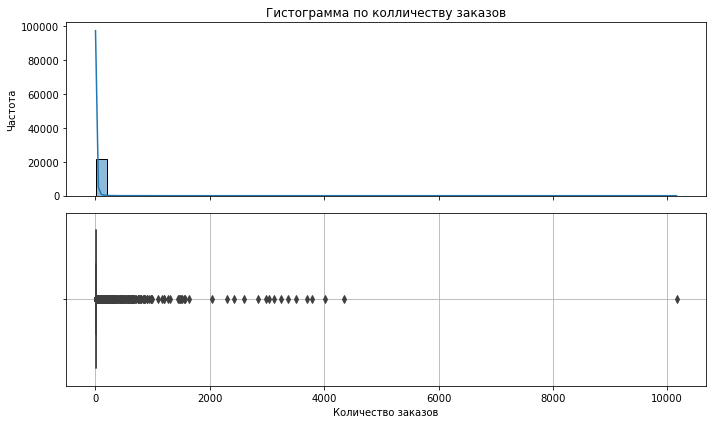

In [50]:
#Посмотрим графики

show_kde(df_user, 'sum_orders', 'Гистограмма по колличеству заказов', 'Частота', 'Количество заказов', True, 50)

Видим что такие большие выбросы сильно искажают нам распределение, отфильтруемся по 95 перцентилю

In [51]:
#Отфильтруемся по 95 перцентилю и посмотрим на графики
filtr_user = df_user['sum_orders'].quantile(0.95)
df_user_f= df_user[df_user['sum_orders'] < filtr_user].copy()
df_user_f['sum_orders'].describe()

count    20711.000000
mean         4.009077
std          5.011307
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max         30.000000
Name: sum_orders, dtype: float64

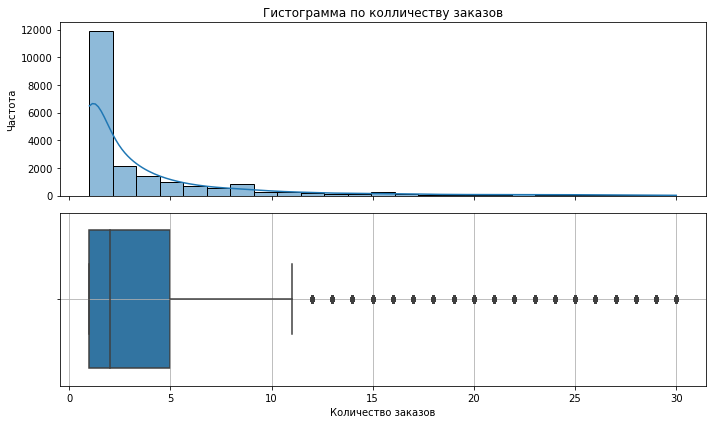

In [52]:
show_kde(df_user_f, 'sum_orders', 'Гистограмма по колличеству заказов', 'Частота', 'Количество заказов', True, 25)

In [53]:
#Изучим статистические показатели по количеству билетов
df_user_f['mean_tickets'].describe()

count    20711.000000
mean         2.740862
std          0.968161
min          1.000000
25%          2.000000
50%          3.000000
75%          3.000000
max         11.000000
Name: mean_tickets, dtype: float64

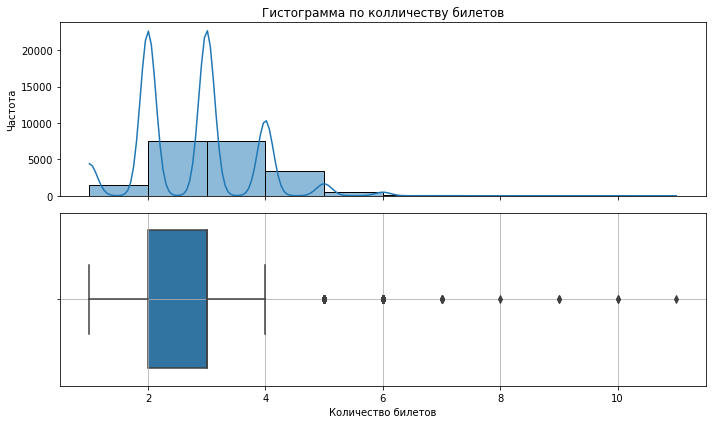

In [54]:
show_kde(df_user_f, 'mean_tickets', 'Гистограмма по колличеству билетов', 'Частота', 'Количество билетов', True, 10)

In [55]:
#Изучим статистические показатели по среднему количеству дней между покупками
df_user_f['mean_days_since_prev'].describe()

count    12387.000000
mean        17.094545
std         22.908407
min          0.000000
25%          1.000000
50%          9.500000
75%         22.200001
max        148.000000
Name: mean_days_since_prev, dtype: float64

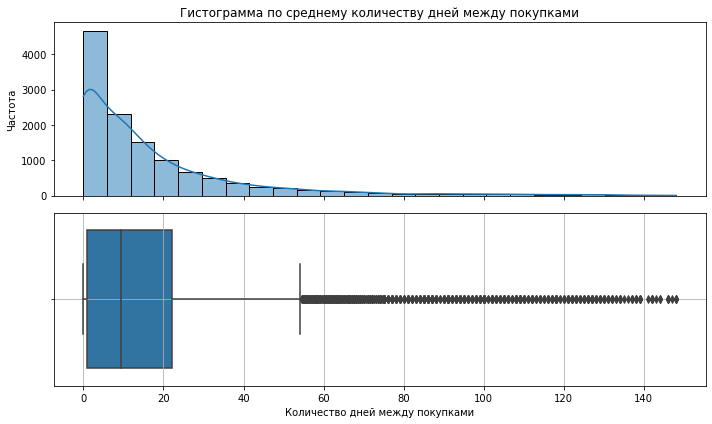

In [56]:
show_kde(df_user_f, 'mean_days_since_prev', 'Гистограмма по среднему количеству дней между покупками', 'Частота', 'Количество дней между покупками', True, 25)

In [57]:
# Проверим сколько удалено строк датасета
a, b = len(df_user), len(df_user_f)
print(" Было строк в исходном датасете", a,
      '\n', "Осталось строк в датасете после обработки", b,
      '\n', "Удалено строк в датасете после обработки", a-b,
      '\n', "Процент потерь", round((a-b)/a*100, 2))

 Было строк в исходном датасете 21832 
 Осталось строк в датасете после обработки 20711 
 Удалено строк в датасете после обработки 1121 
 Процент потерь 5.13


In [58]:
#Посмотрим статестические показатели по отфильтрованному датасету
user_count_f = len(df_user_f)
mean_rev_f = round(df_user_f['mean_revenue'].sum() / df_user_f['sum_orders'].sum(), 2)
two_ord_f = round(df_user_f['is_two'].mean(), 2)
five_ord_f = round(df_user_f['is_five'].mean(), 2)
print(' Количество пользователей всего:', user_count_f,
      '\n', 'Средняя выручка за один заказ:', mean_rev_f,
      '\n', 'Доля пользователей, совершивших 2 и более заказа:', two_ord_f,
       '\n', 'Доля пользователей, совершивших 5 и более заказа:', five_ord_f)

 Количество пользователей всего: 20711 
 Средняя выручка за один заказ: 136.31 
 Доля пользователей, совершивших 2 и более заказа: 0.6 
 Доля пользователей, совершивших 5 и более заказа: 0.25


In [59]:
df_user_f.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 20711 entries, 0 to 21831
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   user_id               20711 non-null  object        
 1   first_order           20711 non-null  datetime64[ns]
 2   last_order            20711 non-null  datetime64[ns]
 3   device_f_o            20711 non-null  category      
 4   region_f_o            20711 non-null  object        
 5   service_name_f_o      20711 non-null  object        
 6   event_f_o             20711 non-null  category      
 7   sum_orders            20711 non-null  int16         
 8   mean_revenue          20711 non-null  float32       
 9   mean_tickets          20711 non-null  int8          
 10  mean_days_since_prev  12387 non-null  float32       
 11  is_two                20711 non-null  bool          
 12  is_five               20711 non-null  bool          
dtypes: bool(2), cate

### Промежуточный вывод

1. <b><i>Общая информация о данных</b></i>
- Датасет содержит 21832 строк и 13 колонок;
- Для более корректного исследования датасет был отфильтрован от выбросов по столбцу sum_orders, итоговый размер датасета после преобразований 20711 строк и 13 колонок;
- Колонки содержат следующую информацию:
    - user_id - уникальный индекс пользователя;
    - first_order - дата первого 
    - last_order - дата последнего заказа;
    - device_f_o - устройство, с которого был сделан первый заказ;
    - region_f_o - регион, в котором был сделан первый заказ;
    - service_name_f_o - название билетного партнёра, к которому обращались при первом заказе;
    - event_f_o - жанр первого посещённого мероприятия (используйте поле event_type_main );
    - sum_orders - общее количество заказов;
    - mean_revenue - средняя выручка с одного заказа в рублях;
    - mean_tickets - среднее количество билетов в заказе;
    - mean_days_since_prev - среднее время между заказами;
    - is_two - совершил ли пользователь 2 и более заказа;
    - is_five - совершил ли пользователь 5 и более заказов;
    

2. <b><i>Пропуски</b></i>
- Пропуски содержатся только в столбце mean_days_since_prev, они означают что пользователь совершил только один заказ и больше не возвращался, такие данные мы не удаляем;

    
3. <b><i>Из датасета получены данные:</b></i>  
- Количество пользователей всего: 20711 
- Средняя выручка за один заказ: 136.31 
- Доля пользователей, совершивших 2 и более заказа: 0.6 
- Доля пользователей, совершивших 5 и более заказа: 0.25

Все данные после агрегаций распределены равномерно, выбросы отсутстсвуют, данные готовы к дальнейшему анализу.


## 4. Исследовательский анализ данных
Исследуем признаки, влияющие на возврат пользователей, то есть на совершение повторного заказа.

### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу

#### Задача 4.1.1. Изучите распределение пользователей по признакам.

In [60]:
#Напишем функцию для распределения
def group_data(df, column, title, xlabel, ylabel, rot, x, y):
    val = df[column].value_counts().sort_values(ascending=False)
    perc = round(df[column].value_counts(normalize=True) * 100, 2)
    print('Распределение пользователей в числах:')
    print(val)
    print('\nРаспределение пользователей в долях (%):')
    print(perc)
    #Визуализируем данные
    plt.figure(figsize=(x, y))
    #Создаем график
    df[column].value_counts(normalize=True).plot(
        kind = 'bar',
        rot = rot,
        legend = False,
        title = title)
    #Редактируем график
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid()

    plt.show()

Распределение пользователей в числах:
концерты    9167
другое      5152
театр       4065
стендап     1069
спорт        763
выставки     401
ёлки          94
Name: event_f_o, dtype: int64

Распределение пользователей в долях (%):
концерты    44.26
другое      24.88
театр       19.63
стендап      5.16
спорт        3.68
выставки     1.94
ёлки         0.45
Name: event_f_o, dtype: float64


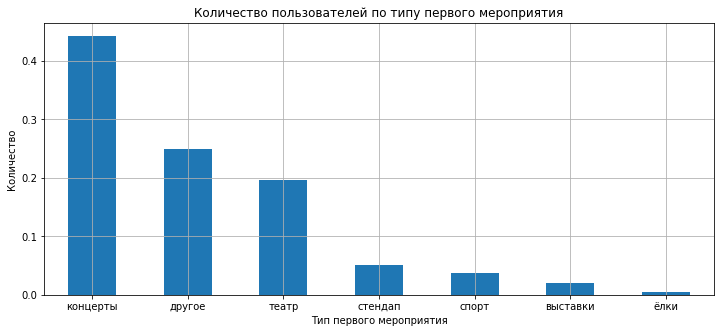

In [61]:
#Изучим распределение пользователей по типу их первого мероприятия
group_data(df_user_f, 
           'event_f_o',
           'Количество пользователей по типу первого мероприятия', 
           'Тип первого мероприятия', 
           'Количество', 
           0, 
           12, 5)

Чаще всего первый заказ у пользователя это билет на концерт (44.26%), на втором месте по популярности это другое (24.88) и на третьем месте театр (19.63), реже всего первым заказом для пользователя является билет на елки (0.45), что может объясняться сезонностью мероприятий, это единственная категория мероприятий привязанная к конкретному празднику(новый год).

Распределение пользователей в числах:
mobile     17180
desktop     3531
Name: device_f_o, dtype: int64

Распределение пользователей в долях (%):
mobile     82.95
desktop    17.05
Name: device_f_o, dtype: float64


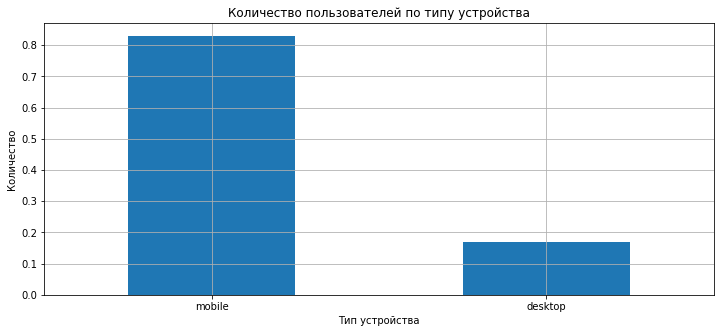

In [62]:
#Изучим распределение пользователей по типу устройства, с которого совершена первая покупка;
group_data(df_user_f,
           'device_f_o',
           'Количество пользователей по типу устройства',
           'Тип устройства',
           'Количество', 
           0, 
           12, 5)

Видим что чаще всего первый заказ совершается с мобильного телефона(82,95%), реже с компьютера(17,05%).

Распределение пользователей в числах:
каменевский регион          6775
североярская область        3596
широковская область         1181
озернинский край             659
малиновоярский округ         516
                            ... 
тихогорская область            2
сосноводолинская область       1
светолесский край              1
яснопольский округ             1
верхозёрский край              1
Name: region_f_o, Length: 81, dtype: int64

Распределение пользователей в долях (%):
каменевский регион          32.71
североярская область        17.36
широковская область          5.70
озернинский край             3.18
малиновоярский округ         2.49
                            ...  
тихогорская область          0.01
сосноводолинская область     0.00
светолесский край            0.00
яснопольский округ           0.00
верхозёрский край            0.00
Name: region_f_o, Length: 81, dtype: float64


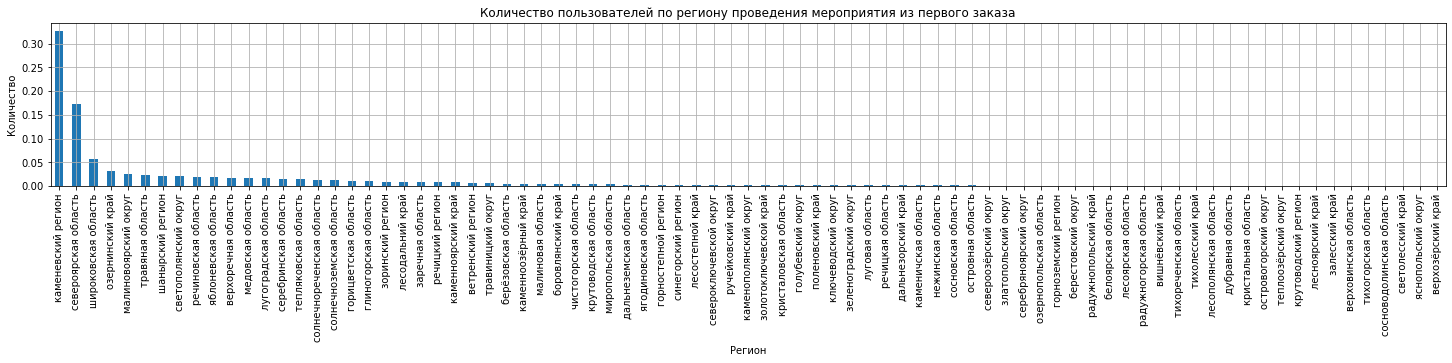

In [63]:
#Изучим распределение пользователей по региону проведения мероприятия из первого заказа;
group_data(df_user_f, 
           'region_f_o',
           'Количество пользователей по региону проведения мероприятия из первого заказа',
           'Регион',
           'Количество',
           90,
           25, 3)

Видим что в лидерах два региона - каменевский регион (32,71%) и североярская область (17.36%);

Распределение пользователей в числах:
билеты без проблем        4948
мой билет                 2840
лови билет                2703
билеты в руки             2420
облачко                   2107
весь в билетах            1232
лучшие билеты             1130
прачечная                  549
край билетов               438
дом культуры               339
яблоко                     308
тебе билет                 297
городской дом культуры     209
мир касс                   199
за билетом                 196
быстробилет                159
showticket                 155
выступленияру               92
восьмёрка                   82
быстрый кассир              55
crazy ticket                42
росбилет                    40
радио ticket                36
реестр                      27
телебилет                   27
цвет и билет                21
шоу начинается              18
карандашру                  14
кино билет                   9
вперёд                       7
билет по телефону            6
т

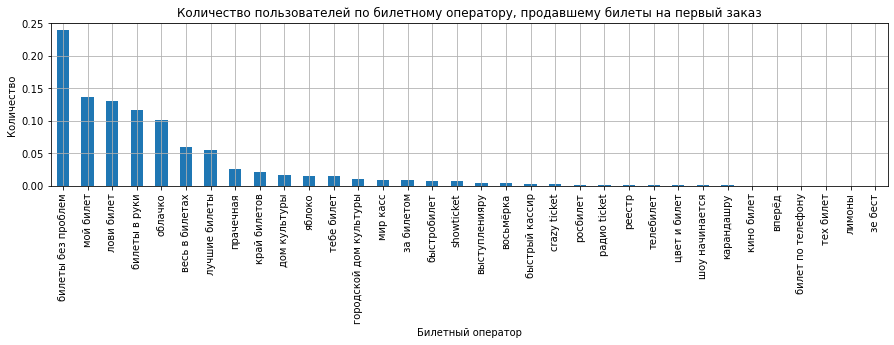

In [64]:
#Изучим распределение пользователей по билетному оператору, продавшему билеты на первый заказ
group_data(df_user_f, 
           'service_name_f_o', 
           'Количество пользователей по билетному оператору, продавшему билеты на первый заказ', 
           'Билетный оператор', 
           'Количество', 
           90, 
           15, 3)

Видим что чаще всего заказы делают через "билеты без проблем" (23.89%), затем идут "мой билет" (13.71%), "лови билет" (13.05%), "билеты в руки" (11.68%) и "облачко" (10.17%).

Изучили распределение пользователей по следующим признакам: 
- по типу их первого мероприятия;
- по типу устройства, с которого совершена первая покупка;
- по региону проведения мероприятия из первого заказа;
- по билетному оператору, продавшему билеты на первый заказ.

Видим что пользователи распределены не равномерно, есть выраженные пики:
    
   - Чаще всего первый заказ у пользователя это билет на концерт (44.26%), на втором месте по популярности это другое (24.88%) и на третьем месте театр (19.63%), остальные категории мероприятий сильно отстают по популярности, концерт - самый универсальный тип мероприятия, затрагивающий как подростков так и взрослых людей. 
    
   - Так же намного больше пользователей совершили свой первый заказ через мобильное устройство (82.95%), в современном мире пользователю удобнее все заказать через телефон, компьютер полностью отходит на задний план;
    
   - По месту проведения мероприятия в лидерах два региона - каменевский регион (32,71%) и североярская область (17.36%), это может быть связано с тем что туда артисты и музыканты приезжают чаще и количество мероприятий больше, чем в других регионах;
    
   - Первый заказ пользователи чаще всего делают через "билеты без проблем" (23.89%), затем идут "мой билет" (13.71%), "лови билет" (13.05%), "билеты в руки" (11.68%) и "облачко" (10.17%), возможно у данных операторов удобнее интерфейс, выгоднее цены или больше эксклюзивных мероприятий.

Обобщая результат можем сказать что чаще всего первый заказ пользователь делает через мобильный телефон(82,95%) покупая билет на концерт (44.26%) в каменевском регионе (32.71%) через сервис "билеты без проблем" (23.89%).

#### Задача 4.1.2. Проанализируйте возвраты пользователей:

In [65]:
#Проанализируем возвраты пользователей
df_first_ev = df_user_f.groupby(by = 'event_f_o').agg(
    user_count = ('user_id', 'count'),
    mean_is_two = ('is_two', 'mean')).sort_values(by = 'user_count', ascending=False)
print(df_first_ev)

           user_count  mean_is_two
event_f_o                         
концерты         9167     0.601942
другое           5152     0.576087
театр            4065     0.618204
стендап          1069     0.594013
спорт             763     0.539974
выставки          401     0.630923
ёлки               94     0.553191


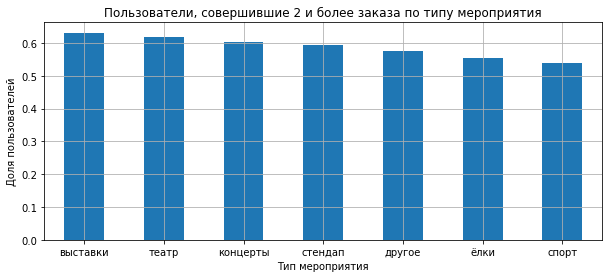

In [66]:
#Визуализируем данные
def fig(df, column, kind, title, xlabel, ylabel):
    plt.figure(figsize=(10, 4))
    #Создаем график
    df[column].plot(
        kind = kind,
        rot = 0,
        legend = False,
        title = title)
    #Редактируем график
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid()

    plt.show()
    
fig(df_first_ev.sort_values(by = 'mean_is_two', ascending=False),
    'mean_is_two',
    'bar',
    'Пользователи, совершившие 2 и более заказа по типу мероприятия',
    'Тип мероприятия',
    'Доля пользователей')

Видим что доля возвращенйи в каждой категории примерно одинаковая от 54% до 63%, то есть возвращается в каждой категории чуть больше половины пользователей, если учитывать количество пользователей всего в категории, то оптимально выглядит ситуация с театрами(по процентам лидирует выставки(63%), но количество пользователей слишком маленькое для адекватной оценки ситуации), куда чаще покупаются билеты и процент возвратов 62% чуть выше среднего по всем категориям. В целом видим что категория мероприятия на возврат пользователей никак не влияет.

In [67]:
#Проанализируем возвраты пользователей по типу устройства, с которого совершена первая покупка;
df_first_dev = df_user_f.groupby(by = 'device_f_o').agg(
    user_count = ('user_id', 'count'),
    mean_is_two = ('is_two', 'mean')).sort_values(by = 'user_count', ascending=False)
print(df_first_dev)

            user_count  mean_is_two
device_f_o                         
mobile           17180     0.591444
desktop           3531     0.620221


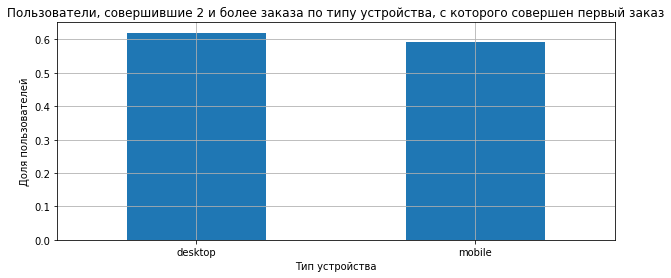

In [68]:
fig(df_first_dev.sort_values(by = 'mean_is_two', ascending=False),
    'mean_is_two',
    'bar',
    'Пользователи, совершившие 2 и более заказа по типу устройства, с которого совершен первый заказ',
    'Тип устройства',
    'Доля пользователей')

Видим что ситуация не отличается, лидирует по возвратам компьютер 62%, но и на мобильных устройствах возвраты 59%, не смотря на большую разницу в количестве пользователей.

In [69]:
#Проанализируем возвраты пользователей по региону проведения мероприятия из первого заказа
df_first_reg = df_user_f.groupby(by = 'region_f_o').agg(
    user_count = ('user_id', 'count'),
    mean_is_two = ('is_two', 'mean')).sort_values(by = 'user_count', ascending=False).head(10)
print(df_first_reg)

                      user_count  mean_is_two
region_f_o                                   
каменевский регион          6775     0.606642
североярская область        3596     0.620968
широковская область         1181     0.631668
озернинский край             659     0.541730
малиновоярский округ         516     0.550388
травяная область             468     0.598291
шанырский регион             462     0.645022
светополянский округ         436     0.639908
речиновская область          421     0.617577
яблоневская область          397     0.579345


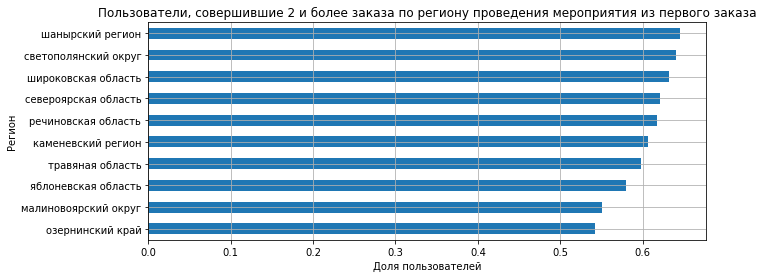

In [70]:
#Визуализируем, для более понятного результата оставим топ 10 регионов
fig(df_first_reg.sort_values(by = 'mean_is_two', ascending=True),
    'mean_is_two',
    'barh',
    'Пользователи, совершившие 2 и более заказа по региону проведения мероприятия из первого заказа',
    'Доля пользователей',
    'Регион')


По регионам лидирует шанырский регион 65%, но количество пользователей, сделавших заказ всего 462 чел., на фоне крупных регионов ситуация не сильно отличатеся, широковская область с 1181 чел. имеет долю возвратов 63%, в целом все значения примерно одинаковые в диапазоне от 54% (озернинский край 659 чел) до 64% (шанырский регион 462 чел), разброс в 10% не такой значительный так как по количеству пользователей максимальное и минимальное значение относятся к регионам с количеством пользователей <700, различия и доли могут быть нестабильными при такой маленькой выборке.

In [71]:
#Проанализируем возвраты пользователей по билетному оператору, продавшему билеты на первый заказ.
df_first_serv = df_user_f.groupby(by = 'service_name_f_o').agg(
    user_count = ('user_id', 'count'),
    mean_is_two = ('is_two', 'mean')).sort_values(by = 'user_count', ascending=False).head(10)
print(df_first_serv)

                    user_count  mean_is_two
service_name_f_o                           
билеты без проблем        4948     0.585691
мой билет                 2840     0.591901
лови билет                2703     0.593785
билеты в руки             2420     0.606612
облачко                   2107     0.599430
весь в билетах            1232     0.612825
лучшие билеты             1130     0.595575
прачечная                  549     0.602914
край билетов               438     0.639269
дом культуры               339     0.628319


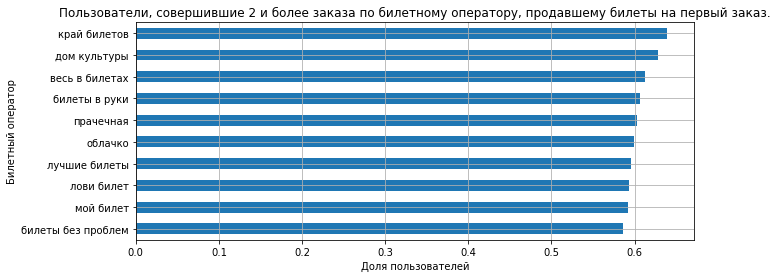

In [72]:
#Визуализируем, для более понятного результата оставим топ 10 сервисов
fig(df_first_serv.sort_values(by = 'mean_is_two', ascending=True),
    'mean_is_two',
    'barh',
    'Пользователи, совершившие 2 и более заказа по билетному оператору, продавшему билеты на первый заказ.',
    'Доля пользователей',
    'Билетный оператор')

Видим что опять процент возвратов находится в диапазоне от 59%(билеты без проблем) до 64% (край билетов), оператор с наибольшим количеством пользователей имеет наименьший процент возвратов (билеты без проблем 4948 чел 59%), но от общего процента по исследованию он не отличается.

В целом какой то сильной зависимости от определенной категории к возврщениям в данных не наблюдается, где то диапазон процентов чуть выше (например при анализе возвращений пользователей по региону проведения мероприятия из первого заказа диапазон 10%) но это связано с большой разницей в количестве пользователей в каждом регионе от  397 до 6775, такая неравномерная выборка в каждом сегмнте выдает разброс чуть больше чем при анализе в других категориях, но все равно везде наблюдаем что процент возращений около 60%. Каких то успешных точек входа не наблюдается.


**Гипотеза 1. Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.**

Гипотеза не подтверждается, так как процент возвращений при первом заказе на спортивные мероприятия - 54%, процент возвращений пользователей, оформивших свой первый заказ на концерты - 60%, учитывая количество пользователей в данных сегментах (спорт - 763, концерты - 9167) какой то зависимости возвращений от типа мероприятия не наблюдается.


**Гипотеза 2. В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.**

Гипотеза не подтверждается, так как максимальная доля повторных заказов относится к шанырскому региону с числом пользователей 462 и процентов возвращений 65%, в то время как в наиболее активном каменевском регионе с числом пользователей 6775 процент возвращений всего 61%. Но учитывая количество пользователей в данных сегментах  какой то зависимости возвращений от активного не наблюдается.

### 4.2. Исследование поведения пользователей через показатели выручки и состава заказа

Изучим количественные характеристики заказов пользователей, чтобы узнать среднюю выручку сервиса с заказа и количество билетов, которое пользователи обычно покупают.

#### Задача 4.2.1. Проследите связь между средней выручкой сервиса с заказа и повторными заказами.

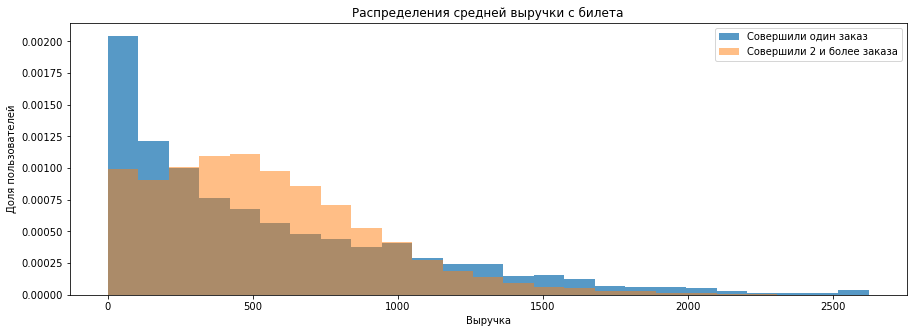

In [73]:
#Построим сравнительные гистограммы распределения средней выручки с билета
df_avg_one = df_user_f[df_user_f['is_two'] == False]
df_avg_two = df_user_f[df_user_f['is_two'] == True]

plt.figure(figsize=(15,5))
plt.hist(df_avg_one['mean_revenue'],
                   bins=25,
                   alpha=0.75,
                   density=True)
plt.hist(df_avg_two['mean_revenue'],
                   bins=25,
                   alpha=0.5,
                   density=True)
plt.title('Распределения средней выручки с билета')
plt.xlabel('Выручка')
plt.ylabel('Доля пользователей')
plt.legend(['Совершили один заказ', 'Совершили 2 и более заказа'])

In [74]:
print('Средняя выручка (1 заказ):', df_avg_one['mean_revenue'].mean())
print('Средняя выручка (2 заказа):', df_avg_two['mean_revenue'].mean())

print('\nМедиана выручки (1 заказ):', df_avg_one['mean_revenue'].median())
print('Медиана выручки (2 заказа):', df_avg_two['mean_revenue'].median())

Средняя выручка (1 заказ): 544.6964111328125
Средняя выручка (2 заказа): 547.6871337890625

Медиана выручки (1 заказ): 378.54498291015625
Медиана выручки (2 заказа): 494.7040100097656


Видим что для пользователей, совершивших только один заказ характерна более низкая выручка, пик гистограммы приходится на диапазон от 0 до 100, основной массив пользователей сконцентрирован в диапазоне от 0 до 500 но чем больше выручка, тем меньше пользователей, в то время как у пользователей совершивших две и более покупки пик приходится на диапазон 400-500 и сконцентрированы они в основном в диапазоне от 0 до 1000. 

Так же существуют пользователи совершившие один заказ но с высокой выручкой, на гистограмме видим длинный хвост уходящий вправо, это сравнивает среднюю выручку по группам, но медиана выдает подтвержение тому что больше выручки приносят пользователи, совершившие два и более заказа.

#### Задача 4.2.2. Сравните распределение по средней выручке с заказа в двух группах пользователей:
#### - совершившие 2–4 заказа
#### - совершившие 5 и более заказов

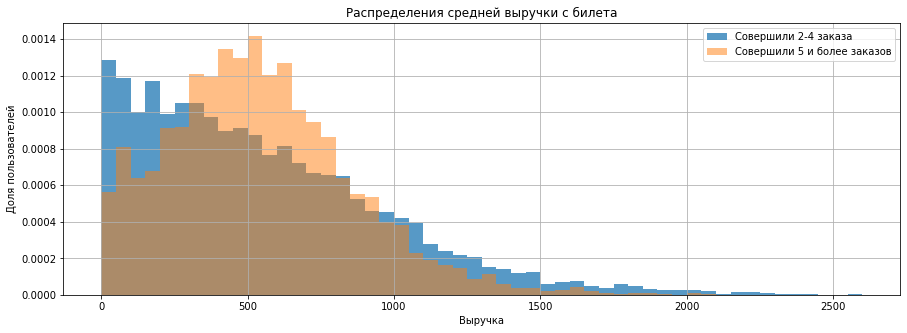

In [75]:
#Сравним распределение по средней выручке с заказа в двух группах пользователей совершивших 2–4 заказа и совершившие 5 и более заказов.
df_avg_four = df_user_f[(df_user_f['sum_orders'] >= 2) & (df_user_f['sum_orders'] <= 4)]
df_avg_five = df_user_f[df_user_f['is_five'] == True] 
min_value_ord = int(df_user_f['mean_revenue'].min())
max_value_ord = int(df_user_f['mean_revenue'].max())
plt.figure(figsize=(15,5))
plt.hist(df_avg_four['mean_revenue'],
                   bins = range(min_value_ord, max_value_ord+1, 50),
                   alpha=0.75,
                   density=True)
plt.hist(df_avg_five['mean_revenue'],
                   bins = range(min_value_ord, max_value_ord+1, 50),
                   alpha=0.5,
                   density=True)
plt.title('Распределения средней выручки с билета')
plt.xlabel('Выручка')
plt.ylabel('Доля пользователей')
plt.grid(True)
plt.legend(['Совершили 2-4 заказа', 'Совершили 5 и более заказов'])

In [76]:
print('Средняя выручка (2-4 заказа):', df_avg_four['mean_revenue'].mean())
print('Средняя выручка (5 и более заказов):', df_avg_five['mean_revenue'].mean())

print('\nМедиана выручки (2-4 заказа):', df_avg_four['mean_revenue'].median())
print('Медиана выручки (5 и более заказов):', df_avg_five['mean_revenue'].median())

Средняя выручка (2-4 заказа): 551.6318969726562
Средняя выручка (5 и более заказов): 542.2798461914062

Медиана выручки (2-4 заказа): 472.3175048828125
Медиана выручки (5 и более заказов): 515.0642700195312


Видим что средняя выручка не сильно отличается, но по медианам у тех кто делает 2-4 заказа медиана меньше чем у тех кто делает 5 и более заказов, что говорит о том что у более лояльных пользователей средний чек выше даже без учета редких дорогих покупок(выбросов), возможно в эту группу входят более обеспеченные люди которые покупаю более дорогие билеты. 

Так же об этом говорит форма распределений, для группы 2-4 заказа пик распределения приходится на диапазон 0-100, скорее всего они покупают билеты на скидках или горящие, стараются больше экономить и редко в принципе делают заказ но правый хвост говорит о том что данная группа чаще соверщает редкие дрогие покупки, в то время как для группы 5 и более пик приходится на 500-600 и основная масса пользователей сконцентрирована в центре, хвосты небольшие, то есть для этой группы выручка более стабильна.  
Можем сформулировать вывод:
У клиентов которые делают больше заказов средний чек выше.

#### Задача 4.2.3. Проанализируйте влияние среднего количества билетов в заказе на вероятность повторной покупки

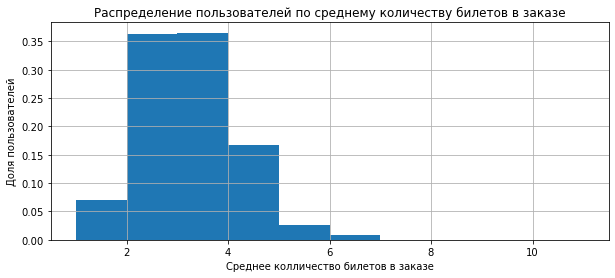

In [77]:
#Изучим распределение пользователей по среднему количеству билетов в заказе ( mean_tickets )

plt.figure(figsize=(10,4))
plt.hist(df_user_f['mean_tickets'],
                   bins=10,
                   density=True)
plt.title('Распределение пользователей по среднему количеству билетов в заказе')
plt.xlabel('Среднее колличество билетов в заказе')
plt.ylabel('Доля пользователей')
plt.grid(True)

In [78]:
print('Среднее количество билетов:', df_user_f['mean_tickets'].mean())
print('Медиана:', df_user_f['mean_tickets'].median())

Среднее количество билетов: 2.7408623436821014
Медиана: 3.0


Видим что основная масса пользователей сконцентрирована в диапазоне от 2 до 4 билетов, распределение нормальное хвосты небольшие, медиана не сильно отличается от среднего, выбросов нет 

In [79]:
#Разделим пользователей на несколько сегментов по среднему количеству билетов в заказе
bins = [1, 2, 3, 5, float('inf')]
labels = [
    '1 билет',           #[1, 2)  
    '2 билета',          #[2, 3) 
    '3-4 билета',        #[3, 5) 
    '5+ билетов']         #[5, inf) 

df_user_f['segment'] = pd.cut(df_user_f['mean_tickets'], bins=bins, labels=labels, right=False)

print(df_user_f['segment'].value_counts())

3-4 билета    11005
2 билета       7524
1 билет        1463
5+ билетов      719
Name: segment, dtype: int64


In [80]:
round(df_user_f['segment'].value_counts(normalize=True) * 100, 2)

3-4 билета    53.14
2 билета      36.33
1 билет        7.06
5+ билетов     3.47
Name: segment, dtype: float64

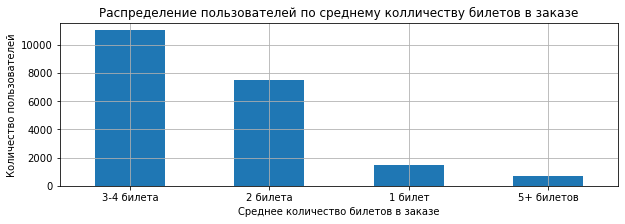

In [81]:
#Визуализируем
plt.figure(figsize=(10, 3))
#Создаем график
df_user_f['segment'].value_counts().plot(
    kind = 'bar',
    rot = 0,
    legend = False,
    title = f'Распределение пользователей по среднему колличеству билетов в заказе')
#Редактируем график
plt.xlabel('Среднее количество билетов в заказе')
plt.ylabel('Количество пользователей')
plt.grid()

plt.show()

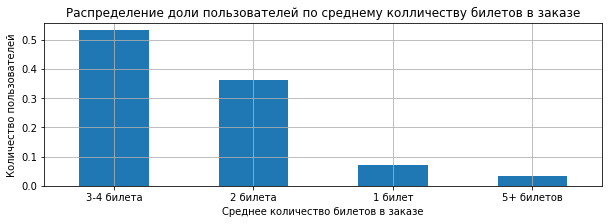

In [82]:
#Визуализируем
plt.figure(figsize=(10, 3))
#Создаем график
df_user_f['segment'].value_counts(normalize=True).plot(
    kind = 'bar',
    rot = 0,
    legend = False,
    title = f'Распределение доли пользователей по среднему колличеству билетов в заказе')
#Редактируем график
plt.xlabel('Среднее количество билетов в заказе')
plt.ylabel('Количество пользователей')
plt.grid()

plt.show()

In [83]:
#Посчитаем долю пользователей совершивших повторные заказы для каждой категории
segment_stats = df_user_f.groupby('segment').agg(
                                        user_count = ('user_id', 'count'),
                                        is_two = ('is_two', 'sum')).reset_index()
segment_stats['is_two_percent'] = round((segment_stats['is_two'] / segment_stats['user_count']) * 100, 2)

print(segment_stats)

      segment  user_count  is_two  is_two_percent
0     1 билет        1463     288           19.69
1    2 билета        7524    5015           66.65
2  3-4 билета       11005    6866           62.39
3  5+ билетов         719     182           25.31


Видим что распределение сильно сконцентрировано в зонах 3-4 билета и 2 билета, почти 90% пользователей (53% и 36%) попадают в два сегмента: те, кто берет 2, 3 или 4 билета, люди редко покупают один билет и редко покупают 5+ билетов.
Видим что чаще всего возврващаются пользователи со средним количеством билетов в заказе - 2 - 67%, затем идет группа 3-4 билета - 62%, реже всех возвращаются те, кто заказывают в среднем один билет - 20%. В целом никаких аномальных значений не наблюдается. Наша основная самая лояльная и многочисленная аудитория - пользователь совершающий заказ на 2-4 билета, они занимают 90% от всех пользователей в выборке и чаще возвращаются на плтаформу.

### 4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки

#### Задача 4.3.1. Проанализируйте, как день недели, в которой была совершена первая покупка, влияет на поведение пользователей.

In [84]:
#По данным даты первого заказа выделимс день недели
df_user_f['weekday'] = df_user_f['first_order'].dt.day_of_week
print(df_user_f['weekday'])

0        1
1        1
2        5
3        3
4        6
        ..
21826    2
21827    1
21828    3
21830    1
21831    2
Name: weekday, Length: 20711, dtype: int64


In [85]:
#Посчитаем долю пользователей совершивших повторные заказы для каждого дня недели
weekday_stats = df_user_f.groupby('weekday').agg(
                                        user_count = ('user_id', 'count'),
                                        is_two = ('is_two', 'sum')).reset_index()
weekday_stats['is_two_percent'] = round((weekday_stats['is_two'] / weekday_stats['user_count']) * 100, 0)

print(weekday_stats)

   weekday  user_count  is_two  is_two_percent
0        0        2809    1729            62.0
1        1        3009    1803            60.0
2        2        2958    1803            61.0
3        3        3023    1761            58.0
4        4        3158    1847            58.0
5        5        3118    1881            60.0
6        6        2636    1527            58.0


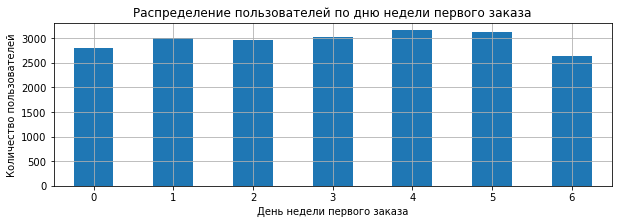

In [86]:
#Визуализируем
plt.figure(figsize=(10, 3))
#Создаем график
weekday_stats['user_count'].plot(
    kind = 'bar',
    rot = 0,
    legend = False,
    title = f'Распределение пользователей по дню недели первого заказа')
#Редактируем график
plt.xlabel('День недели первого заказа')
plt.ylabel('Количество пользователей')
plt.grid()

plt.show()

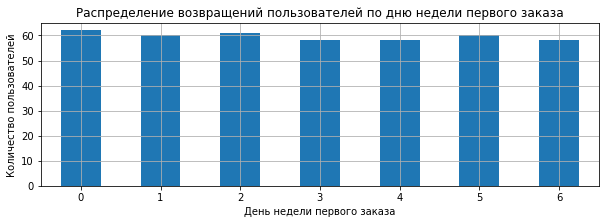

In [87]:
#Визуализируем возвращения по дням недели
plt.figure(figsize=(10, 3))
#Создаем график
weekday_stats['is_two_percent'].plot(
    kind = 'bar',
    rot = 0,
    legend = False,
    title = f'Распределение возвращений пользователей по дню недели первого заказа')
#Редактируем график
plt.xlabel('День недели первого заказа')
plt.ylabel('Количество пользователей')
plt.grid()

plt.show()

Распределение равномерное, есть небольшие пики - чаще всего люди делают первый заказ в пятницу(4) - 3158 польз., и в субботу(5) - 3118 польз., реже всего в воскресенье(6) - 2636 польз., что логично, люди планируют отдых в вечер пятницы и на выходные, в воскресенье не до планирования отдыха, надо готовиться к рабочей неделе. По возвратам процент находится в диапазоне от 58 до 62, разброс недольшой можем сделать вывод что возвраты не зависят от дня недели.

#### Задача 4.3.2. Изучите, как средний интервал между заказами влияет на удержание клиентов.

Пользователей, совершивших 2-4 заказа будем называть группой 1, пользователей, совершивших 5 и более заказов назовем группой 2

In [88]:
#Рассчитаем среднее время между заказами для двух групп пользователе
mean_time1 = round(df_avg_four['mean_days_since_prev'].mean(), 0)
mean_time2 = round(df_avg_five['mean_days_since_prev'].mean(), 0)
median_time1 = round(df_avg_four['mean_days_since_prev'].median(), 0)
median_time2 = round(df_avg_five['mean_days_since_prev'].median(), 0)

print('Среднее время между заказами для группы 1:', mean_time1)
print('Среднее время между заказами для группы 2:', mean_time2)
print('Медианное время между заказами для группы 1:', median_time1)
print('Медианное время между заказами для группы 2:', median_time2)

Среднее время между заказами для группы 1: 21.0
Среднее время между заказами для группы 2: 11.0
Медианное время между заказами для группы 1: 9.0
Медианное время между заказами для группы 2: 10.0


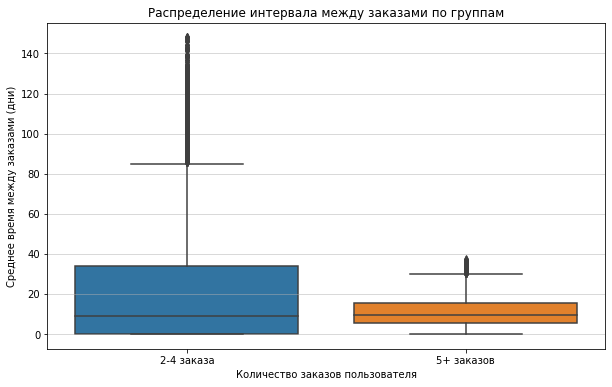

In [89]:
#Визулизируем
plot_df = pd.concat([
    df_avg_four.assign(group='2-4 заказа'),
    df_avg_five.assign(group='5+ заказов')]) 

plt.figure(figsize=(10, 6))
sns.boxplot(data=plot_df, x='group', y='mean_days_since_prev')

plt.title('Распределение интервала между заказами по группам')
plt.xlabel('Количество заказов пользователя')
plt.ylabel('Среднее время между заказами (дни)')
plt.grid(axis='y', alpha=0.6)
plt.show() 

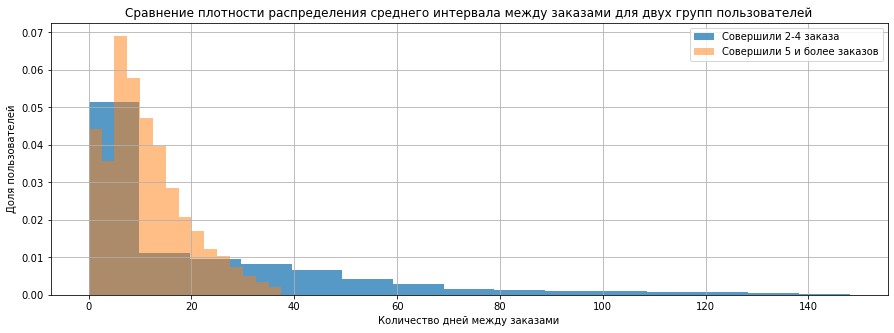

In [90]:
plt.figure(figsize=(15,5))
plt.hist(df_avg_four['mean_days_since_prev'],
                   bins=15,
                   alpha=0.75,
                   density=True)
plt.hist(df_avg_five['mean_days_since_prev'],
                   bins=15,
                   alpha=0.5,
                   density=True)
plt.title('Сравнение плотности распределения среднего интервала между заказами для двух групп пользователей')
plt.xlabel('Количество дней между заказами')
plt.ylabel('Доля пользователей')
plt.grid(True)
plt.legend(['Совершили 2-4 заказа', 'Совершили 5 и более заказов'])

Пользователи из 2 группы(5+) более предсказуемы и стабильны, выбросов практически нет, основная масса пользователей возвращается через 10-11 дней, в то время как группа 1(2-4 заказа) имеет более широкий размах и большое количество выбросов (возварщаются на платформу через 80 и более дней), и основная масса сконцентрирована в диапазоне от 0 до 30 дней, не смотря на похожие медианы мы видим большой разброс в средних значениях (20 дней у группы 1против 9 дней у группы 2) за счет выбросов у группы 1, это указывает на неоднородность сегмента: часть пользователей возвращается стабильно, а другая часть делает покупки эпизодически, с большими перерывами.

У активных пользователей (5+) оранжевая кривая на распределении уже и выше типичный средний интервал меньше, пользователи этой группы более предсказуемы, стабильны и чаще возварщаются. У группы 1(2-4 заказа) хвост синей кривой уходит вправо, для этой группы более характерны большие перерывы между покупками, они менее вовлечены. Для группы 1(2-4 заказа) рекомендуется поработать над вовлеченностью, возможно чаще слать напоминания о скидках и акциях, предлагать промокоды при возвращении и т.д.

#### 4.4. Корреляционный анализ количества покупок и признаков пользователя

Изучим, какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок.

In [91]:
# Вычисляем матрицу Phi_k
from phik import phik_matrix
correlation_matrix = df_user_f[['device_f_o',
                                'region_f_o',
                                'event_f_o',
                                'mean_revenue',
                                'mean_tickets',
                                'mean_days_since_prev',
                                'sum_orders']].phik_matrix(interval_cols = ['sum_orders', 'mean_revenue', 'mean_tickets', 'mean_days_since_prev'])

# Выводим корреляцию рейтинга с остальными признаками
print('Корреляционная матрица с коэффициентом phi_k для переменной sum_orders')
total_orders = correlation_matrix[['sum_orders']].sort_values(by='sum_orders', ascending=False)
print(total_orders)

Корреляционная матрица с коэффициентом phi_k для переменной sum_orders
                      sum_orders
sum_orders              1.000000
mean_days_since_prev    0.489436
mean_tickets            0.296356
mean_revenue            0.264225
device_f_o              0.051627
region_f_o              0.034910
event_f_o               0.034547


In [92]:
#Проверим разброс данных в sum_orders
df_user_f['sum_orders'].describe()

count    20711.000000
mean         4.009077
std          5.011307
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max         30.000000
Name: sum_orders, dtype: float64

In [93]:
#Зазделим количество заказов на сегменты
bins = [1, 2, 5, float('inf')]
labels = [
    '1 заказ',           #[1, 2)  
    '2-4 заказа',        #[2, 5) 
    '5+ заказов']        #[5, inf) 

df_user_f['order_segment'] = pd.cut(df_user_f['sum_orders'], bins=bins, labels=labels, right=False)

print(df_user_f['order_segment'].value_counts())

1 заказ       8360
2-4 заказа    7142
5+ заказов    5209
Name: order_segment, dtype: int64


In [94]:
# Вычисляем матрицу Phi_k
from phik import phik_matrix
correlation_matrix_2 = df_user_f[['device_f_o',
                                'region_f_o',
                                'event_f_o',
                                'mean_revenue',
                                'mean_tickets',
                                'mean_days_since_prev',
                                'order_segment']].phik_matrix(interval_cols = ['mean_revenue', 'mean_tickets', 'mean_days_since_prev'])

# Выводим корреляцию рейтинга с остальными признаками
print('Корреляционная матрица с коэффициентом phi_k для переменной order_segment')
total_orders = correlation_matrix_2[['order_segment']].sort_values(by='order_segment', ascending=False)
print(total_orders)

Корреляционная матрица с коэффициентом phi_k для переменной order_segment
                      order_segment
order_segment              1.000000
mean_days_since_prev       0.377251
mean_tickets               0.373976
mean_revenue               0.297970
region_f_o                 0.107834
event_f_o                  0.040821
device_f_o                 0.015675


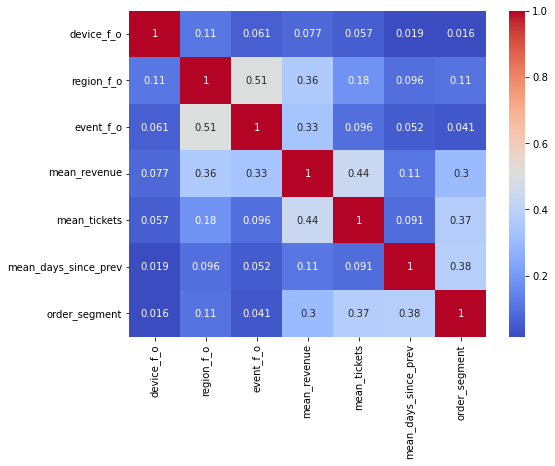

In [95]:
#Визуализируем тепловую карту
plt.figure(figsize = (8, 6))
sns.heatmap(data = correlation_matrix_2, annot = True, cmap = 'coolwarm')
plt.show()

Видим сильную корреляцию 0.38 между количеством заказов и средним колличсеством дней между заказами - чем больше заказов тем меньше время между ними, это подтверждает теорию что у группы пользователей с 5+ заказами средний интервал между заказами меньше, пользователи этой группы более предсказуемы, стабильны и чаще возвращаются.

Кореляция 0.37 между количеством заказов и средним колличеством билетов в заказе - пользователи, заказывающие часто берут больше билетов, так же сильная связь есть между средней выручкой и количеством заказов  - 0.30 тут все логично, больше заказов - больше выручка. 

Регион, тип события и устройство, с которого делается заказ не имеют сильной связи с количеством заказов у пользователя. 

## 5. Общие выводы и рекомендации
Для анализа из представленной базы данных был собран датасет `df` содержащий 15 столбцов и 290611 строк с информацией о пользователях, их заказах и мероприятиях. Данные подготовлены к дальнейшему анализу, типы данных   скорректированы, пропуски проанализированы и дубликаты удалены, создан дополнительный столбец для удобства анализа данных.

Так как в исходном датасете выручка представлена в двух валютах - rub и kzt, для дальнейшей работы был создан столбец revenue_rub, показывающий всю выручку в единой валюте - rub. Так же были выявлены выбросы и отрицательная выручка в столбце revenue_rub, датасет был отфильтрован от выбросов и отрицательной выручки для более ясного дальнейшего анализа. Количество строк в датасете после фильтрации - 287223.

Так же в процессе исследовательского анализа был создан дополнительный датасет отображающий профиль пользователя, из датасета получены следующие данные:
 
- Количество пользователей всего: 20711 
- Средняя выручка за один заказ: 136.31 
- Доля пользователей, совершивших 2 и более заказа: 0.6 
- Доля пользователей, совершивших 5 и более заказа: 0.25

В процессе анализа были получены ответы на интересующие вопросы:

   **4.1.** Сильной зависимости от определенной категории к возвращению на платформу в данных не наблюдается.

Пользователи в датасете распределены не равномерно, есть выраженные пики:
    
   - Чаще всего первый заказ у пользователя это билет на концерт (44.26%), на втором месте по популярности это другое (24.88%) и на третьем месте театр (19.63%), остальные категории мероприятий сильно отстают по популярности.
    
   - Намного больше пользователей совершили свой первый заказ через мобильное устройство (82.95%).
    
   - По месту проведения мероприятия в лидерах два региона - каменевский регион (32,71%) и североярская область (17.36%), это может быть связано с размером региона и тем что туда артисты и музыканты приезжают чаще и количество мероприятий больше, чем в других регионах;
    
   - Первый заказ пользователи чаще всего делают через "билеты без проблем" (23.89%), затем идут "мой билет" (13.71%), "лови билет" (13.05%), "билеты в руки" (11.68%) и "облачко" (10.17%), возможно у данных операторов удобнее интерфейс, выгоднее цены или больше эксклюзивных мероприятий.

Обобщая результат можем сказать что типичный пользователь делает первый заказ через мобильный телефон(82,95%) покупая билет на концерт (44.26%) в каменевском регионе (32.71%) через сервис "билеты без проблем" (23.89%).
   
**Гипотеза 1** не подтверждается, так как процент возвращений при первом заказе на спортивные мероприятия - 54%, процент возвращений пользователей, оформивших свой первый заказ на концерты - 60%, учитывая количество пользователей в данных сегментах (спорт - 763, концерты - 9167) какой то зависимости возвращений от типа мероприятия не наблюдается.

**Гипотеза 2** не подтверждается, так как максимальная доля повторных заказов относится к шанырскому региону с числом пользователей 462 и процентов возвращений 65%, в то время как в наиболее активном каменевском регионе с числом пользователей 6775 процент возвращений всего 61%. Но учитывая количество пользователей в данных сегментах какой то зависимости возвращений от активного не наблюдается.

**4.2** Пользователи с одним заказом приносят меньше выручки. Клиенты с 2-4 заказами чаще экономят, а их выручка менее стабильна. Пользователи с 5+ заказами имеют более стабильную выручку и высокий средний чек.

Около 90% пользователей покупают в среднем 2–4 билета. Наибольшая возвращаемость наблюдается у покупателей двух билетов (67%), затем у группы 3–4 билета (62%). Таким образом, покупатели 2–4 билетов — основная и наиболее лояльная аудитория платформы.

**4.3** Чаще всего люди делают первый заказ в пятницу - 3158 польз., и в субботу - 3118 польз., реже всего в воскресенье - 2636 польз.Возвращения на плтаформу не зависят от дня недели.

Группа 5+ заказов стабильна и чаще возвращается в среднем через 10-11 дней. Для группы 2-4 заказа более характерны большие перерывы между покупками(0-30 дней, но есть те кто возварщаются на платформу через 80 и более дней), они менее вовлечены, часть пользователей возвращается стабильно, а другая часть делает покупки эпизодически, с большими перерывами.

**4.4.1** Видим сильную корреляцию 0.38 между количеством заказов и средним количеством дней между заказами - чем больше заказов тем меньше время между ними, это подтверждает теорию что у группы пользователей с 5+ заказами средний интервал между заказами меньше, пользователи этой группы более предсказуемы, стабильны и чаще возвращаются.

Кореляция 0.37 между количеством заказов и средним колличеством билетов в заказе - пользователи, заказывающие часто берут больше билетов, так же сильная связь есть между средней выручкой и количеством заказов  - 0.30 тут все логично, больше заказов - больше выручка. 

Регион, тип события и устройство, с которого делается заказ не имеют сильной связи с количеством заказов у пользователя. 

**Рекомендации**

На основе результатов анализа я бы порекомендовала:
- так как для пользователей с 1 заказом выручка низкая, можно для новых пользователей сделать скидку при первом заказе нескольких билетов, что позволит увеличить средний чек у пользователей с одним заказом;
- при покупке 5+ билетов и 1 билета можно предложить скидку на следующий заказ что бы стимулировать пользователей возвращаться на платформу;
- поработать над интервалом между заказами пользователей сделавших 2-4 заказа, возможно предложить им скидку/предложение с ограничением по времени (например действует в течении 10 дней после заказа);
- Выгодные дни для рекламной компании - пятница и суббота;
- Уделять повышенное внимание мобильному приложению, основная часть пользователей заказывает через него, при сбоях/неудачных обновлениях может сильно уронить выручку;

## 6. Публикация проекта
https://github.com/YanaS0/M2.2/tree/main